In [3]:
# ══ ALTERED DISTRIBUTION: settings + 3 predictors (ideal-alpha / ctx-count / in-arch log) ══
# Task is the SAME Markov-noise ICL task as folder 6, with ONE change: the two successors
# of each ruled state are UNEQUAL.  Each state draws p1 ~ U(0.25, 0.75), p2 = 1 - p1, so a
# signal emission picks successor s0 w.p. p1 and s1 w.p. p2 (both >= 0.25).  This removes the
# 0.5/0.5 symmetry that let GD "equalise" without reading the in-context count ratio.
#
# Three reference predictors (NO training):
#   ideal  : ideal-alpha   -- Bayes floor that KNOWS the true (s0,s1) AND true (p1,p2)
#                             p[s0]+=a*p1 ; p[s1]+=a*p2 ; noise=(1-a)/n_noise   (lowest possible CE)
#   ctx    : ctx-count      -- empirical in-context successor frequencies (a perfect count-reader);
#                             UNCHANGED from folder 6 -> it already estimates the unequal ratio
#   inarch : in-architecture log readout (IDENTICAL construction to folder 8): the W* induction
#                             circuit's frequency f read out as softmax[log(f+δ)-logΣ+logα ; log noise]
#                             = α·(f+δ)/Σ(f+δ).  The best LEGIT hand readout (only ops the model has).
#
# This cell only DEFINES + COMPUTES CEs; the next two cells plot (CE-vs-alpha, then per-position).

SPLIT = 'train'                                          # 'test' or 'train'
SHOW  = dict(ideal=True, ctx=True, inarch=True, trained=True)    # which curves to compute/plot
# 'trained' = the GD model (train_identical_arch.py): IDENTICAL architecture to the in-arch
# log readout (2 disentangled attn + residual GELU FFN head). Silently skipped until trained.

# in-arch log readout floors δ per α (STRICTLY in-architecture readout; see inarch_dist below).
# Carried over verbatim from folder 8 (grid-searched there via _inarch_best.py for the equal-prob
# task); re-tune for this altered distribution if you want the exact CE-optimal δ here.
INARCH_DELTA   = {0.1: 0.1, 0.2: 0.01, 0.3: 0.01, 0.4: 0.003, 0.5: 0.003,
                  0.6: 0.001, 0.7: 0.001, 0.8: 0.001, 0.9: 0.001}
_INARCH_DEFAULT = 0.001

# ── FRESH-DATA option (same altered distribution, generated on the fly) ────────
USE_FRESH  = False          # True -> fresh generated points; False -> load dataset/<split>/data_x_{thr}.pt
N_POINTS   = 10000          # fresh sequences per alpha (only if USE_FRESH)
FRESH_SEED = 1423         # base RNG seed (reproducible). None -> new draw each run.

DATA_DIR    = 'dataset'    # this folder's dataset/  (written by data_generation.py)
MODELS_DIR  = 'models'     # GD checkpoints (written by train_identical_arch.py)
TRAINED_TAG = 'idarch'     # model_{TAG}_x_{thr}.pth / metrics_{TAG}_x_{thr}.json
# Per-α override of the trained tag. 0.8 from scratch is stuck at the 1.59 'equalise' basin
# (GD can't find the count-reader from random init → α=0.8 optimisation phase transition);
# the warm-start-from-0.9 model (train_identical_arch.py init_from) reaches the 1.42 basin.
TRAINED_OVERRIDE = {0.7: "idarch_ws06", 0.8: "idarch_ws09"}   # warm-starts; falls back to TRAINED_TAG for others
DEVICE      = 'cuda:0'
N_SEQS      = 20000         # cap when loading from disk
EVAL_BATCH  = 200         # mini-batch size for GPU forward passes (bounds peak memory on a contested box)
# Exact training split (must mirror train_identical_arch.py's CONFIG: seed=7, val_frac=0.15,
# NOT per-threshold overridden -> applies identically to every alpha, incl. warm-starts).
TRAIN_EXACT_SPLIT = True     # SPLIT='train' -> evaluate on the EXACT 17k rows GD trained on
                             # (excludes the 3k held-out val rows), instead of the raw first N_SEQS rows.
TRAIN_SPLIT_SEED  = 7        # must equal train_identical_arch.py CONFIG['seed']
TRAIN_SPLIT_VAL_FRAC = 0.15  # must equal train_identical_arch.py CONFIG['val_frac']
TOKEN_START = 100          # CE on tokens 100–200 (last half; seq_len=200)
TOKEN_END   = 200
P1_LOW, P1_HIGH = 0.0, 1.0    # successor-probability sampling range (must match data_generation.py)

import os, glob, json
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

device = torch.device(DEVICE if torch.cuda.is_available() else 'cpu')

# ── W* induction circuit (used by the in-arch log readout) ────────────────────
class _ConcatAttn(nn.Module):
    def __init__(self, input_dim, output_dim):
        super().__init__()
        self.output_dim = output_dim
        self.W_q = nn.Linear(input_dim, output_dim, bias=False)
        self.W_k = nn.Linear(input_dim, output_dim, bias=False)
        self.W_v = nn.Linear(input_dim, output_dim, bias=False)
        self.W_o = nn.Linear(output_dim, output_dim, bias=False)
    def forward(self, x, mask=None):
        Q, K, V = self.W_q(x), self.W_k(x), self.W_v(x)
        s = torch.bmm(Q, K.transpose(1, 2)) / (self.output_dim ** 0.5)
        if mask is not None: s = s + mask
        return torch.cat([x, self.W_o(torch.bmm(F.softmax(s, dim=-1), V))], dim=-1)

class PerfectInductionTransformer(nn.Module):
    def __init__(self, total_vocab, seq_len, vocab_set1):
        super().__init__()
        self.total_vocab = total_vocab; self.seq_len = seq_len; self.vocab_set1 = vocab_set1
        self.initial_dim = total_vocab + seq_len; self.attn_dim = self.initial_dim
        self.layer1 = _ConcatAttn(self.initial_dim, self.attn_dim)
        self.layer2 = _ConcatAttn(self.initial_dim + self.attn_dim, self.attn_dim)
        self.fc_out = nn.Linear(self.initial_dim + 2 * self.attn_dim, total_vocab, bias=False)
        self._set_weights()
    def _set_weights(self):
        V = self.total_vocab; T = self.seq_len; D = self.attn_dim; V_r = self.vocab_set1
        self.layer1.W_q.weight.data = torch.eye(D) * (D ** 0.5)
        T1 = torch.zeros(D, D)
        for k in range(V_r, V): T1[k, :] = -1e9
        for tq in range(T):
            for tk in range(T):
                T1[V + tk, V + tq] = -1e9 if tq == tk else -20.0 * (tq - tk)
        self.layer1.W_k.weight.data = T1.t()
        Wv1 = torch.zeros(D, D); Wv1[:V, :V] = torch.eye(V)
        self.layer1.W_v.weight.data = Wv1
        self.layer1.W_o.weight.data = torch.eye(D)
        in2 = D + D
        Wq2 = torch.zeros(D, in2)
        Wq2[:V_r, :V_r]    = torch.eye(V_r) * (D ** 0.5) * 1000.0
        Wq2[:V_r, D:D+V_r] = torch.eye(V_r) * (D ** 0.5) * 50.0
        for v in range(V): Wq2[V_r, v] = (D ** 0.5) * 10.0
        self.layer2.W_q.weight.data = Wq2
        Wk2 = torch.zeros(D, in2); Wk2[:V, D:D+V] = torch.eye(V)
        for v in range(V_r, V): Wk2[V_r, v] = -50000.0
        self.layer2.W_k.weight.data = Wk2
        Wv2 = torch.zeros(D, in2); Wv2[:V, :V] = torch.eye(V)
        self.layer2.W_v.weight.data = Wv2
        self.layer2.W_o.weight.data = torch.eye(D)
        Wfc = torch.zeros(V, in2 + D); Wfc[:V, in2:in2+V] = torch.eye(V)
        self.fc_out.weight.data = Wfc
    def forward(self, x):
        B, T = x.shape
        tok = F.one_hot(x, num_classes=self.total_vocab).float()
        pos = F.one_hot(torch.arange(T, device=x.device),
                        num_classes=self.seq_len).float().unsqueeze(0).expand(B, T, -1)
        s = torch.cat([tok, pos], dim=-1)
        mask = torch.triu(torch.ones(T, T, device=x.device) * float('-inf'), diagonal=1)
        s = self.layer1(s, mask); s = self.layer2(s, mask)
        return self.fc_out(s)

_WSTAR_CACHE = {}

# ── GD model: DisentangledTransformerMLP (IDENTICAL to train_identical_arch.py / in-arch arch) ──
class ConcatAttentionBlock(nn.Module):
    def __init__(self, input_dim, output_dim):
        super().__init__()
        self.output_dim = output_dim
        self.W_q = nn.Linear(input_dim, output_dim, bias=False)
        self.W_k = nn.Linear(input_dim, output_dim, bias=False)
        self.W_v = nn.Linear(input_dim, output_dim, bias=False)
        self.W_o = nn.Linear(output_dim, output_dim, bias=False)
    def forward(self, x, mask=None):
        Q, K, V = self.W_q(x), self.W_k(x), self.W_v(x)
        scores = torch.bmm(Q, K.transpose(1, 2)) / (self.output_dim ** 0.5)
        if mask is not None: scores = scores + mask
        attn_out = self.W_o(torch.bmm(F.softmax(scores, dim=-1), V))
        return torch.cat([x, attn_out], dim=-1), scores

class DisentangledTransformerMLP(nn.Module):
    def __init__(self, total_vocab, seq_len, attn_dim, mlp_hidden, bias=False, act='gelu'):
        super().__init__()
        self.total_vocab = total_vocab; self.seq_len = seq_len
        self.initial_dim = total_vocab + seq_len
        self.layer1 = ConcatAttentionBlock(self.initial_dim, attn_dim)
        self.layer2 = ConcatAttentionBlock(self.initial_dim + attn_dim, attn_dim)
        D = self.initial_dim + 2 * attn_dim
        self.ff1 = nn.Linear(D, mlp_hidden); self.ff2 = nn.Linear(mlp_hidden, D)
        self.act = nn.GELU() if act == 'gelu' else nn.ReLU()
        self.fc_out = nn.Linear(D, total_vocab, bias=bias)
    def forward(self, x):
        B, T = x.shape
        tok = F.one_hot(x, num_classes=self.total_vocab).float()
        pos = F.one_hot(torch.arange(T, device=x.device),
                        num_classes=self.seq_len).float().unsqueeze(0).expand(B, T, -1)
        s = torch.cat([tok, pos], dim=-1)
        mask = torch.triu(torch.ones(T, T, device=x.device) * float('-inf'), diagonal=1)
        s, _ = self.layer1(s, mask); s, _ = self.layer2(s, mask)
        s = s + self.ff2(self.act(self.ff1(s)))
        return self.fc_out(s)

_TRAINED_CACHE = {}
def _load_trained(thr, seq_len, V):
    """Load the GD checkpoint for this α (config read from its metrics json). None if missing."""
    key = (round(thr, 3), seq_len, V)
    if key in _TRAINED_CACHE: return _TRAINED_CACHE[key]
    tag = TRAINED_OVERRIDE.get(round(thr, 3), TRAINED_TAG)
    mp = os.path.join(MODELS_DIR, f'model_{tag}_x_{thr}.pth')
    cp = os.path.join(MODELS_DIR, f'metrics_{tag}_x_{thr}.json')
    if not os.path.exists(mp):
        _TRAINED_CACHE[key] = None; return None
    cfg = json.load(open(cp)).get('config', {}) if os.path.exists(cp) else {}
    ad = int(cfg.get('attn_dim', V + seq_len)); mh = int(cfg.get('mlp_hidden', 128))
    act = cfg.get('mlp_act', 'gelu'); bias = bool(cfg.get('bias', True))
    m = DisentangledTransformerMLP(V, seq_len, ad, mh, bias=bias, act=act).to(device)
    m.load_state_dict(torch.load(mp, map_location=device, weights_only=True)); m.eval()
    _TRAINED_CACHE[key] = m; return m

@torch.no_grad()
def trained_dist(thr, seq_len, V, x):
    """GD model softmax distribution over the CE window [B,W,V]. None if no checkpoint."""
    m = _load_trained(thr, seq_len, V)
    if m is None: return None
    logits = m(x.to(device))[:, TOKEN_START:TOKEN_END]
    return F.softmax(logits, dim=-1)

@torch.no_grad()
def _batched_ce_from_dist(dist_fn, x, y, V, batch=None):
    """Chunked CE: dist_fn(x_chunk)->prob dist [b,W,V] on device. Bounds peak GPU memory
    to O(batch) instead of O(N), freeing each chunk before the next -- needed when the
    shared box leaves little free GPU memory (see CLAUDE.md §6 gotchas)."""
    batch = batch or EVAL_BATCH
    B = x.shape[0]; total_nll = 0.0; total_n = 0
    for i in range(0, B, batch):
        xb = x[i:i+batch].to(device)
        p  = dist_fn(xb).reshape(-1, V).clamp_min(1e-12)
        yb = y[i:i+batch, TOKEN_START:TOKEN_END].to(device).reshape(-1)
        total_nll += (-torch.log(p[torch.arange(len(yb), device=device), yb])).sum().item()
        total_n   += len(yb)
        del xb, p, yb
        if device.type == 'cuda': torch.cuda.empty_cache()
    return total_nll / total_n

def trained_ce(thr, seq_len, V, x, y):
    m = _load_trained(thr, seq_len, V)
    if m is None: return None
    def dist_fn(xb):
        return F.softmax(m(xb)[:, TOKEN_START:TOKEN_END], dim=-1)
    return _batched_ce_from_dist(dist_fn, x, y, V)

# ── Data: loader (disk) + fresh generator (same altered scheme as data_generation.py) ──
def load_data(split, thr, n_cap=N_SEQS):
    blob = torch.load(os.path.join(DATA_DIR, split, f'data_x_{thr}.pt'), weights_only=False)
    N = min(n_cap, blob['x'].shape[0])
    blob['x'] = blob['x'][:N]; blob['y'] = blob['y'][:N]
    for k in ('transitions', 'trans_probs'):
        if k in blob: blob[k] = blob[k][:N]
    return blob['x'], blob['y'], int(blob['seq_len']), int(blob['total_vocab']), blob

def load_train_exact_split(thr):
    """Reproduce train_identical_arch.py's 90/10 split EXACTLY (same seed, same permutation,
    same val_frac) and return only the tr_idx rows -- i.e. the actual data GD trained on.
    Loads the FULL on-disk train blob first (uncapped by N_SEQS) since the split is defined
    over all n_full rows, then subsets to the training partition."""
    blob = torch.load(os.path.join(DATA_DIR, 'train', f'data_x_{thr}.pt'), weights_only=False)
    n_full = blob['x'].shape[0]
    g = torch.Generator().manual_seed(TRAIN_SPLIT_SEED + 99)
    perm = torch.randperm(n_full, generator=g)
    n_val = max(1, int(round(TRAIN_SPLIT_VAL_FRAC * n_full)))
    tr_idx = perm[n_val:]
    out = dict(blob)
    out['x'] = blob['x'][tr_idx]; out['y'] = blob['y'][tr_idx]
    for k in ('transitions', 'trans_probs'):
        if k in blob: out[k] = [blob[k][j] for j in tr_idx.tolist()]
    print(f'  [exact-split] thr={thr}: n_full={n_full}  n_val={n_val}  n_train={len(tr_idx)}')
    return out['x'], out['y'], int(out['seq_len']), int(out['total_vocab']), out

def generate_data(split, thr, n_points, seq_len=200, vocab_set1=10, total_vocab=20, seed='cfg'):
    """Fresh ALTERED-distribution sequences (unequal p1,p2 per state), vectorised."""
    base = FRESH_SEED if seed == 'cfg' else seed
    rng = (np.random.default_rng() if base is None
           else np.random.default_rng(base + (1 if split == 'train' else 2) + int(round(thr * 1000))))
    B, V_sig, V = int(n_points), vocab_set1, total_vocab
    order     = rng.random((B, V_sig, V_sig)).argsort(axis=2)
    trans_arr = order[:, :, :2].astype(np.int64)                  # [B, V_sig, 2]
    p1        = rng.uniform(P1_LOW, P1_HIGH, size=(B, V_sig))
    prob_arr  = np.stack([p1, 1.0 - p1], axis=2)                  # [B, V_sig, 2]
    seq  = np.empty((B, seq_len + 1), dtype=np.int64)
    last = np.full(B, -1, dtype=np.int64); bidx = np.arange(B)
    for t in range(seq_len + 1):
        is_sig = rng.random(B) < thr
        has    = last >= 0
        state  = np.where(has, last, 0)
        u      = rng.random(B)
        coin   = (u >= prob_arr[bidx, state, 0]).astype(np.int64)  # 0 w.p. p1 else 1
        succ   = trans_arr[bidx, state, coin]
        first  = rng.integers(0, V_sig, B)
        noise  = rng.integers(V_sig, V, B)
        tok    = np.where(is_sig, np.where(has, succ, first), noise)
        last   = np.where(is_sig, tok, last)
        seq[:, t] = tok
    x = torch.from_numpy(seq[:, :-1]).contiguous().long()
    y = torch.from_numpy(seq[:, 1:]).contiguous().long()
    trans = [{v: trans_arr[b, v] for v in range(V_sig)} for b in range(B)]
    probs = [{v: prob_arr[b, v]  for v in range(V_sig)} for b in range(B)]
    blob = {'x': x, 'y': y, 'seq_len': seq_len, 'total_vocab': V, 'vocab_set1': V_sig,
            'transitions': trans, 'trans_probs': probs, 'threshold': float(thr), 'split': split}
    return x, y, seq_len, V, blob

def get_data(split, thr, use_fresh=False, n_points=None):
    if use_fresh: return generate_data(split, thr, n_points or N_POINTS)
    if split == 'train' and TRAIN_EXACT_SPLIT: return load_train_exact_split(thr)
    return load_data(split, thr)

# Every predictor exposes a *_dist producer returning the per-position distribution over the
# CE window [TOKEN_START,TOKEN_END) as [B, W, V]; the *_ce wrappers just cross-entropy it.
# The diagnostic cell reuses the SAME producers, so plotted bars == the CE distributions.
def _ce_from_win(p_win, y_np):                                  # p_win [B,W,V] (numpy), y_np [B,T]
    yw = y_np[:, TOKEN_START:TOKEN_END]; B, W = yw.shape
    bb = np.arange(B)[:, None]; ww = np.arange(W)[None, :]
    return float((-np.log(np.maximum(p_win[bb, ww, yw], 1e-12))).mean())

# ── PREDICTOR 1: ideal-alpha (knows true table AND true unequal probs) ─────────
def ideal_alpha_dist(blob, alpha):
    x_np = blob['x'].numpy(); trans = blob['transitions']; probs = blob['trans_probs']
    V = int(blob['total_vocab']); V_sig = int(blob['vocab_set1']); n_noise = V - V_sig
    B = x_np.shape[0]; W = TOKEN_END - TOKEN_START
    trans_arr = np.array([[trans[b][v] for v in range(V_sig)] for b in range(B)], dtype=np.int64)
    prob_arr  = np.array([[probs[b][v] for v in range(V_sig)] for b in range(B)], dtype=np.float64)
    p_win = np.zeros((B, W, V), dtype=np.float64)
    last_sig = np.zeros(B, dtype=np.int64)
    for t in range(TOKEN_END):
        is_sig = x_np[:, t] < V_sig
        last_sig = np.where(is_sig, x_np[:, t], last_sig)
        if t < TOKEN_START: continue
        s0 = trans_arr[np.arange(B), last_sig, 0]; s1 = trans_arr[np.arange(B), last_sig, 1]
        q0 = prob_arr[np.arange(B), last_sig, 0];  q1 = prob_arr[np.arange(B), last_sig, 1]
        p = np.zeros((B, V), dtype=np.float64)
        p[:, V_sig:] = (1.0 - alpha) / n_noise
        p[np.arange(B), s0] += alpha * q0
        p[np.arange(B), s1] += alpha * q1
        p_win[:, t - TOKEN_START] = p
    return p_win

def ideal_alpha_ce(blob, alpha):
    return _ce_from_win(ideal_alpha_dist(blob, alpha), blob['y'].numpy())

# ── PREDICTOR 2: ctx-count (empirical successor frequencies; unchanged logic) ──
def ctx_count_dist(blob, alpha):
    x_np = blob['x'].numpy()
    V = int(blob['total_vocab']); V_sig = int(blob['vocab_set1'])
    n_noise = V - V_sig; B = x_np.shape[0]; W = TOKEN_END - TOKEN_START
    trans_counts = np.zeros((B, V, V_sig), dtype=np.float64)
    pending      = np.zeros((B, V), dtype=np.float64)
    last_ruled   = np.full(B, -1, dtype=np.int64)
    def _step(col):
        tok_col = x_np[:, col]; is_ruled = tok_col < V_sig
        ri = np.where(is_ruled)[0]
        if len(ri):
            rt = tok_col[ri]
            oh = (np.arange(V_sig) == rt[:, None]).astype(np.float64)
            np.add.at(trans_counts, ri, pending[ri, :, None] * oh[:, None, :])
            pending[ri, :] = 0.0; pending[ri, rt] = 1.0; last_ruled[ri] = rt
        ni = np.where(~is_ruled)[0]
        if len(ni): pending[ni, tok_col[ni]] += 1.0
    for i in range(TOKEN_START): _step(i)
    eps = 0.01; p_win = np.zeros((B, W, V), dtype=np.float64)
    for t in range(TOKEN_START, TOKEN_END):
        v = x_np[:, t]; is_sig_q = v < V_sig
        query = np.where(is_sig_q, v, np.maximum(last_ruled, 0))
        cnt = trans_counts[np.arange(B), query]; cnt_s = cnt + eps
        tot_s = cnt_s.sum(axis=1, keepdims=True)
        p = np.zeros((B, V), dtype=np.float64)
        p[:, :V_sig] = cnt_s / tot_s * alpha; p[:, V_sig:] = (1.0 - alpha) / n_noise
        p_win[:, t - TOKEN_START] = p
        _step(t)
    return p_win

def alpha_ce(blob, alpha):
    return _ce_from_win(ctx_count_dist(blob, alpha), blob['y'].numpy())

# ── PREDICTOR 3: in-architecture log readout (IDENTICAL construction to folder 8) ──
@torch.no_grad()
def _wstar_window(seq_len, V, Vs, x):
    """W* induction-circuit output over the CE window [B,W,V] = empirical successor freq f
    (signal cols), via the hand-built W* PerfectInductionTransformer (identical to folder 8)."""
    m = _WSTAR_CACHE.get((V, seq_len, Vs))
    if m is None:
        m = PerfectInductionTransformer(V, seq_len, Vs).to(device).eval(); _WSTAR_CACHE[(V, seq_len, Vs)] = m
    return m(x.to(device))[:, TOKEN_START:TOKEN_END]

@torch.no_grad()
def inarch_dist(thr, seq_len, V, Vs, x, delta=None):
    """STRICTLY in-architecture log readout (attention -> GELU-FFN log -> linear -> softmax):
       softmax[ log(f+δ) - log Σ_sig(f+δ) + log α  (signal) ;  log((1-α)/n)  (noise) ]
       = α·(f+δ)/Σ_sig(f+δ) on signal, (1-α)/n on noise.  NO IPR, NO equalize — only ops the
       trained model has.  This is the best LEGIT hand readout; sits a hair above ctx-count."""
    if delta is None: delta = INARCH_DELTA.get(round(thr, 3), _INARCH_DEFAULT)
    f = _wstar_window(seq_len, V, Vs, x)[..., :Vs].clamp_min(0.0)
    psig = thr * (f + delta) / (f + delta).sum(-1, keepdim=True)
    pn = (1.0 - thr) / (V - Vs)
    return torch.cat([psig, torch.full(psig.shape[:-1] + (V - Vs,), pn, device=device)], dim=-1)

def inarch_ce(thr, seq_len, V, Vs, x, y):
    delta = INARCH_DELTA.get(round(thr, 3), _INARCH_DEFAULT)
    def dist_fn(xb):
        return inarch_dist(thr, seq_len, V, Vs, xb, delta=delta)
    return _batched_ce_from_dist(dist_fn, x, y, V)

# ════════════════════════════════════════════════════════════════════════════════
# COMPUTE the toggled CEs over all alphas (used by the plot in the next cell)
# ════════════════════════════════════════════════════════════════════════════════
if USE_FRESH:
    thresholds = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
else:
    thresholds = sorted(float(os.path.basename(f)[len('data_x_'):-len('.pt')])
                        for f in glob.glob(os.path.join(DATA_DIR, SPLIT, 'data_x_*.pt')))

_src = f'FRESH {N_POINTS}pts (seed={FRESH_SEED})' if USE_FRESH else f'disk N_SEQS={N_SEQS}'
print(f'SPLIT={SPLIT}  data={_src}  window=[{TOKEN_START}:{TOKEN_END}]  device={device}')
print(f'p1~U({P1_LOW},{P1_HIGH}) per state, p2=1-p1   thresholds={thresholds}')
print(f'computing: {[k for k,v in SHOW.items() if v]}\n')

results = {}
for thr in thresholds:
    x, y, seq_len, V, blob = get_data(SPLIT, thr, USE_FRESH, N_POINTS)
    Vs = int(blob['vocab_set1']); r = {}
    if SHOW.get('ideal'):       r['ideal']       = ideal_alpha_ce(blob, thr)
    if SHOW.get('ctx'):         r['ctx']         = alpha_ce(blob, thr)
    if SHOW.get('inarch'):      r['inarch']      = inarch_ce(thr, seq_len, V, Vs, x, y)
    if SHOW.get('trained'):
        _tc = trained_ce(thr, seq_len, V, x, y)
        if _tc is not None: r['trained'] = _tc          # silently skipped until the model is trained
    results[thr] = r
    print(f"  thr={thr:.2f}  " + "  ".join(f"{k}={v:.4f}" for k, v in r.items()))
print('\nDONE. Run the next cell for the CE-vs-alpha plot.')


SPLIT=train  data=disk N_SEQS=20000  window=[100:200]  device=cuda:0
p1~U(0.0,1.0) per state, p2=1-p1   thresholds=[0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
computing: ['ideal', 'ctx', 'inarch', 'trained']

  [exact-split] thr=0.1: n_full=20000  n_val=3000  n_train=17000
  thr=0.10  ideal=2.4454  ctx=2.5146  inarch=2.5299  trained=2.5152
  [exact-split] thr=0.2: n_full=20000  n_val=3000  n_train=17000
  thr=0.20  ideal=2.4374  ctx=2.5079  inarch=2.5166  trained=2.5102
  [exact-split] thr=0.3: n_full=20000  n_val=3000  n_train=17000
  thr=0.30  ideal=2.3662  ctx=2.4357  inarch=2.4494  trained=2.4350
  [exact-split] thr=0.4: n_full=20000  n_val=3000  n_train=17000
  thr=0.40  ideal=2.2457  ctx=2.3123  inarch=2.3275  trained=2.3078
  [exact-split] thr=0.5: n_full=20000  n_val=3000  n_train=17000
  thr=0.50  ideal=2.0818  ctx=2.1464  inarch=2.1629  trained=2.1501
  [exact-split] thr=0.6: n_full=20000  n_val=3000  n_train=17000
  thr=0.60  ideal=1.8790  ctx=1.9420  inarch=1.9641  traine

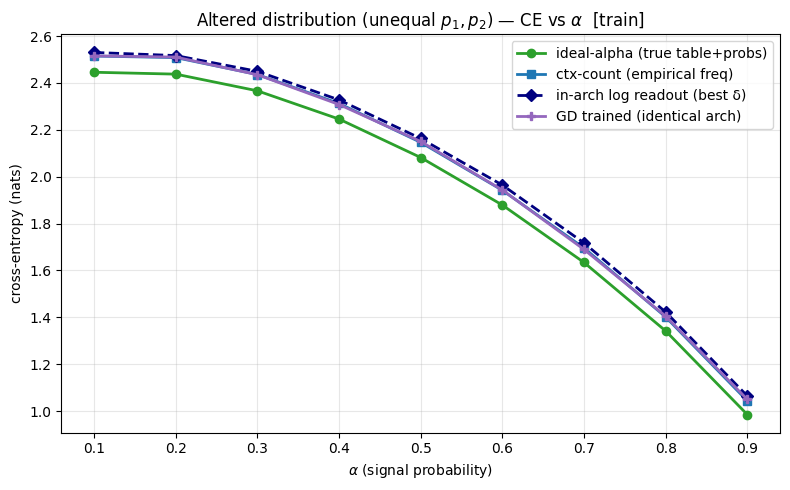

saved ce_vs_alpha_train.png


In [4]:
# ══ PLOT 1: CE vs alpha  (ideal-alpha / ctx-count / in-arch log readout) ═══════
# Uses `results`, `thresholds`, `SHOW`, `SPLIT` from the cell above.
_STYLE = {
    'ideal':   ('ideal-alpha (true table+probs)', 'tab:green',  'o', '-'),
    'ctx':     ('ctx-count (empirical freq)',      'tab:blue',   's', '-'),
    'inarch':  ('in-arch log readout (best δ)',    'navy',       'D', '--'),
    'trained': ('GD trained (identical arch)',     'tab:purple', 'P', '-'),
}
plt.figure(figsize=(8, 5))
for key, (label, color, mk, ls) in _STYLE.items():
    if not SHOW.get(key): continue
    xs = [t for t in thresholds if results[t].get(key) is not None]
    ys = [results[t][key] for t in xs]
    if xs: plt.plot(xs, ys, ls, marker=mk, color=color, label=label, lw=2, ms=6)
plt.xlabel(r'$\alpha$ (signal probability)'); plt.ylabel('cross-entropy (nats)')
plt.title(f'Altered distribution (unequal $p_1,p_2$) — CE vs $\\alpha$  [{SPLIT}]')
plt.grid(alpha=0.3); plt.legend()
plt.tight_layout()
plt.savefig(f'ce_vs_alpha_{SPLIT}.png', dpi=130)
plt.show()
print(f'saved ce_vs_alpha_{SPLIT}.png')


## plot on exact train data(17K datapoints used in train): 

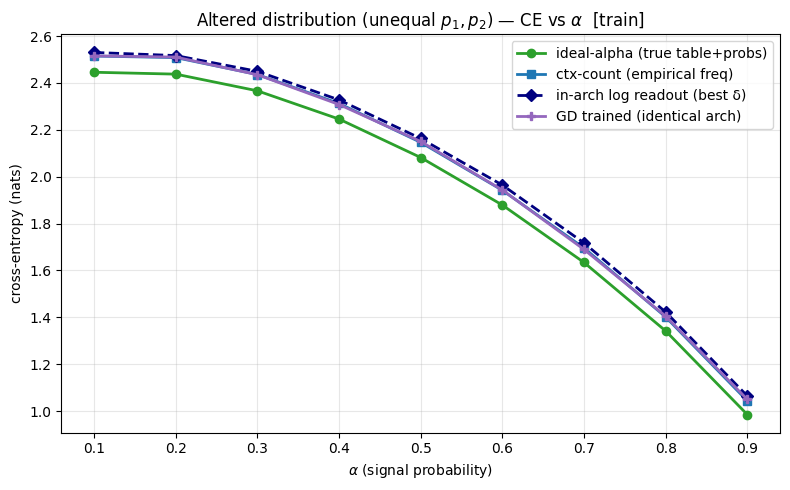

### Trained models in the CE plot — initialization summary

| α | model file | initialization | lr | wd | epochs | best val |
|---|---|---|---|---|---|---|
| 0.1 | `model_idarch_x_0.1.pth` | random | 1e-2 | 0 | 50 | 2.5439 |
| 0.2 | `model_idarch_x_0.2.pth` | random | 1e-2 | 0 | 50 | 2.5378 |
| 0.3 | `model_idarch_x_0.3.pth` | random | 1e-2 | 0 | 50 | 2.4644 |
| 0.4 | `model_idarch_x_0.4.pth` | random | 1e-2 | 0 | 50 | 2.3432 |
| 0.5 | `model_idarch_x_0.5.pth` | random | 1e-2 | 0 | 50 | 2.1782 |
| 0.6 | `model_idarch_x_0.6.pth` | random | 1e-2 | 0 | 50 | 1.9766 |
| **0.7** | `model_idarch_ws06_x_0.7.pth` | **warm-start from α=0.6** | 1e-3 | 1e-2 | 50 | **1.7023** |
| **0.8** | `model_idarch_ws09_x_0.8.pth` | **warm-start from α=0.9** | 1e-3 | 0 | 88 (early stop) | **1.4170** |
| 0.9 | `model_idarch_x_0.9.pth` | random | 1e-2 | 0 | 50 | 1.0739 |

**α=0.7 and α=0.8** hit a phase transition — GD from random init gets stuck in the wrong basin (~2.26 and ~1.59 respectively). Warm-starting from a neighbouring converged checkpoint escapes it.


seq 8 | test | α=0.7 | window [150,200) | focus t=197
Markov chain (this sequence):
  0 -> 6(p=0.17), 4(p=0.83)
  1 -> 1(p=0.31), 5(p=0.69)
  2 -> 1(p=0.65), 6(p=0.35)
  3 -> 4(p=0.79), 2(p=0.21)
  4 -> 9(p=0.89), 0(p=0.11)
  5 -> 2(p=0.59), 6(p=0.41)
  6 -> 1(p=0.59), 0(p=0.41)
  7 -> 3(p=0.79), 0(p=0.21)
  8 -> 0(p=0.30), 3(p=0.70)
  9 -> 2(p=0.57), 0(p=0.43)

x[197]=5  state=5  target y[197]=6
context evidence (state 5): 2=15x, 6=12x, noise=9x
  ideal-alpha (oracle)                    p(y)=0.2853  argmax=2
  ctx-count (empirical freq)              p(y)=0.3102  argmax=2
  in-arch log readout (best δ)            p(y)=0.3087  argmax=2
  GD trained (identical arch)             p(y)=0.3614  argmax=6


/tmp/ipykernel_3226083/940946544.py:140: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


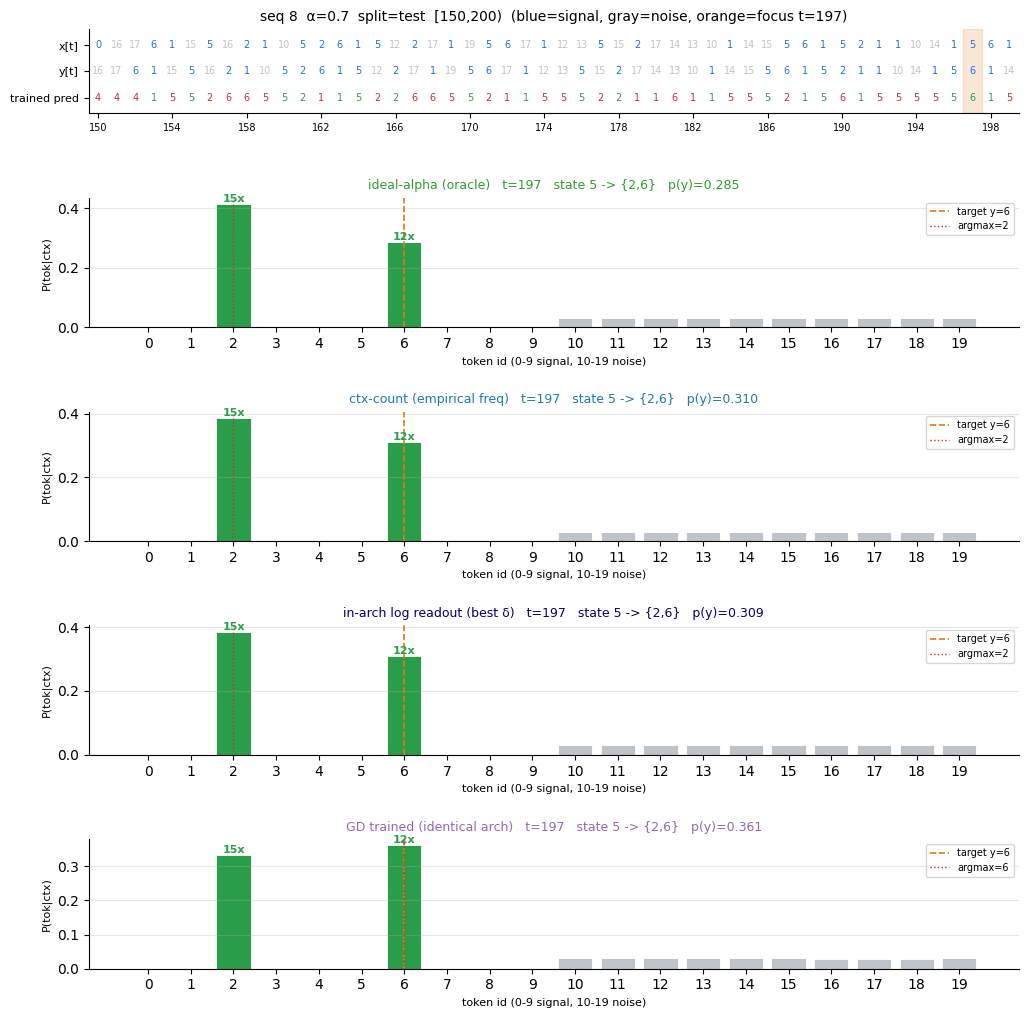

saved → dist_inspect.png


In [10]:
# ══ PLOT 3: DISTRIBUTION DIAGNOSTIC — per-position bar charts with full toggles ══════════
# Token strip + P(token|context) bar charts at a chosen focus position.
# Mirrors the distribution cell in folder-8/analyse.ipynb.
# Run cell 0 first. Edit only the block below.

# ── EDIT HERE ──────────────────────────────────────────────────────────────────────────────
INSPECT_THRESH = 0.7          # which α to inspect
INSPECT_SPLIT  = 'test'       # 'train', 'test', or 'fresh' (fresh generates new seqs on the fly)
N_FRESH_INSP   = 500          # #fresh sequences when INSPECT_SPLIT='fresh'
SEQ_IDX        = 8            # which sequence in the dataset
RANGE_START    = 150          # token strip window start  (must be in [TOKEN_START, TOKEN_END))
RANGE_END      = 200          # token strip window end
FOCUS_POS      = 197          # position for bar charts  (must be in [RANGE_START, RANGE_END))
STRIP_MODEL    = 'trained'    # whose argmax to show in the token strip row: 'ideal','ctx','inarch','trained'
SHOW_INSPECT   = dict(
    ideal   = True,           # ideal-alpha (knows true table AND per-state unequal probs)
    ctx     = True,           # ctx-count (empirical successor frequencies)
    inarch  = True,           # in-arch log readout (hand-built, best δ)
    trained = True,           # GD trained identical arch (silently skipped if checkpoint missing)
)
# ───────────────────────────────────────────────────────────────────────────────────────────
import numpy as np, torch, matplotlib.pyplot as plt, os

_use_fresh_i = (INSPECT_SPLIT == 'fresh')
_split_i     = 'train' if _use_fresh_i else INSPECT_SPLIT
x, y, T, V, blob = get_data(_split_i, INSPECT_THRESH, use_fresh=_use_fresh_i,
                             n_points=(N_FRESH_INSP if _use_fresh_i else None))
Vs = int(blob['vocab_set1']); n_noise = V - Vs

assert TOKEN_START <= RANGE_START < RANGE_END <= TOKEN_END, 'window must lie inside the CE window'
assert RANGE_START <= FOCUS_POS < RANGE_END, 'focus must lie inside the window'
assert 0 <= SEQ_IDX < blob['x'].shape[0], f'SEQ_IDX out of range (have {blob["x"].shape[0]})'

# ── single-sequence blob ────────────────────────────────────────────────────
one = {k: blob[k] for k in ('seq_len', 'total_vocab', 'vocab_set1', 'threshold')}
one['x'] = blob['x'][SEQ_IDX:SEQ_IDX+1]
one['y'] = blob['y'][SEQ_IDX:SEQ_IDX+1]
one['transitions'] = [blob['transitions'][SEQ_IDX]]
one['trans_probs']  = [blob['trans_probs'][SEQ_IDX]]
x_np = one['x'][0].numpy(); y_np = one['y'][0].numpy()
ta   = blob['transitions'][SEQ_IDX]; pr = blob['trans_probs'][SEQ_IDX]
xb   = one['x'].to(device)

def _at(arr, t): return arr[t - TOKEN_START]    # window → CE-window index

# ── compute distributions for toggled curves only ───────────────────────────
ideal_w = ideal_alpha_dist(one, INSPECT_THRESH)[0]  if SHOW_INSPECT.get('ideal')   else None
ctx_w   = ctx_count_dist(one,   INSPECT_THRESH)[0]  if SHOW_INSPECT.get('ctx')     else None
ina_w   = (inarch_dist(INSPECT_THRESH, T, V, Vs, one['x'])[0].cpu().numpy()
           if SHOW_INSPECT.get('inarch') else None)
_tr     = trained_dist(INSPECT_THRESH, T, V, xb)    if SHOW_INSPECT.get('trained') else None
tr_w    = _tr[0].cpu().numpy() if _tr is not None else None

ALL_PRED = [
    ('ideal',   'ideal-alpha (oracle)',           ideal_w, 'tab:green'),
    ('ctx',     'ctx-count (empirical freq)',     ctx_w,   'tab:blue'),
    ('inarch',  'in-arch log readout (best δ)',  ina_w,   'navy'),
    ('trained', 'GD trained (identical arch)',   tr_w,    'tab:purple'),
]
PRED = [(k, lbl, arr, col) for k, lbl, arr, col in ALL_PRED
        if SHOW_INSPECT.get(k) and arr is not None]

# ── last-signal-token state at each position ────────────────────────────────
lr_arr = np.full(T, -1); cur = -1
for t in range(T):
    if x_np[t] < Vs: cur = int(x_np[t])
    lr_arr[t] = cur

fp = FOCUS_POS; state_fp = int(lr_arr[fp])
exp = (int(ta[state_fp][0]), int(ta[state_fp][1])) if state_fp >= 0 else None

# context counts: times each token was emitted FROM state_fp BEFORE fp
ctx_cnt = np.zeros(V, int)
for _t in range(fp):
    if lr_arr[_t] == state_fp: ctx_cnt[int(y_np[_t])] += 1

# ── printout ─────────────────────────────────────────────────────────────────
print(f"seq {SEQ_IDX} | {INSPECT_SPLIT} | α={INSPECT_THRESH} | window [{RANGE_START},{RANGE_END}) | focus t={fp}")
print("Markov chain (this sequence):")
for r in range(Vs):
    q = pr[r]
    print(f"  {r} -> {int(ta[r][0])}(p={float(q[0]):.2f}), {int(ta[r][1])}(p={float(q[1]):.2f})")
if exp:
    print(f"\nx[{fp}]={int(x_np[fp])}  state={state_fp}  target y[{fp}]={int(y_np[fp])}")
    print(f"context evidence (state {state_fp}): {exp[0]}={ctx_cnt[exp[0]]}x, "
          f"{exp[1]}={ctx_cnt[exp[1]]}x, noise={int(ctx_cnt[Vs:].sum())}x")
    for k, lbl, arr, _ in PRED:
        print(f"  {lbl:38s}  p(y)={_at(arr,fp)[int(y_np[fp])]:.4f}  argmax={int(_at(arr,fp).argmax())}")

# ── strip model: fall back to last computed curve if STRIP_MODEL missing ─────
_strip_map = {k: arr for k, _, arr, _ in PRED}
sk = STRIP_MODEL if STRIP_MODEL in _strip_map else (PRED[-1][0] if PRED else None)
sa = _strip_map.get(sk)

# ── figure ───────────────────────────────────────────────────────────────────
BLUE='#1f6feb'; ORANGE='#e07a18'; GRAY='#bfc4cb'; RED='#d62828'; GREEN='#2a9d4a'
rs, re_ = RANGE_START, RANGE_END; cols = re_ - rs; n = len(PRED)
nstrip = 3 if sa is not None else 2
fig = plt.figure(figsize=(max(11, cols*0.24), 3.0 + 2.3*n))
gs  = fig.add_gridspec(1+n, 1, height_ratios=[1.3]+[2.0]*n, hspace=0.7)
ax  = fig.add_subplot(gs[0])
for j, t in enumerate(range(rs, re_)):
    ax.text(j, 2, str(int(x_np[t])), ha='center', va='center', fontsize=7,
            color=(BLUE if x_np[t] < Vs else GRAY))
    ax.text(j, 1, str(int(y_np[t])), ha='center', va='center', fontsize=7,
            color=(BLUE if y_np[t] < Vs else GRAY))
    if sa is not None:
        pt = int(_at(sa, t).argmax())
        ax.text(j, 0, str(pt), ha='center', va='center', fontsize=7,
                color=(GREEN if pt == y_np[t] else RED))
ax.axvspan(fp-rs-0.5, fp-rs+0.5, color=ORANGE, alpha=0.18, zorder=0)
_ytl = ([0,1,2], [f'{sk} pred', 'y[t]', 'x[t]']) if sa is not None else ([0,1], ['y[t]', 'x[t]'])
ax.set_yticks(_ytl[0]); ax.set_yticklabels(_ytl[1], fontsize=8)
ax.set_xticks(range(0, cols, max(1, cols//12)))
ax.set_xticklabels([str(rs+i) for i in range(0, cols, max(1, cols//12))], fontsize=7)
ax.set_xlim(-0.5, cols-0.5); ax.set_ylim(-0.6, nstrip-0.4)
ax.set_title(f"seq {SEQ_IDX}  α={INSPECT_THRESH}  split={INSPECT_SPLIT}  [{rs},{re_})  "
             f"(blue=signal, gray=noise, orange=focus t={fp})", fontsize=10)
for sp in ['top','right']: ax.spines[sp].set_visible(False)

chain = f"state {state_fp} -> {{{exp[0]},{exp[1]}}}" if exp else "(no state yet)"
for r, (key, lbl, arr, col) in enumerate(PRED):
    axb = fig.add_subplot(gs[1+r]); p1 = _at(arr, fp)
    bc = [BLUE if k < Vs else GRAY for k in range(V)]
    if exp:
        for k in exp: bc[k] = GREEN
    axb.bar(range(V), p1, color=bc, edgecolor='white', linewidth=0.6)
    if exp:
        for k in exp:
            axb.text(k, p1[k], f"{int(ctx_cnt[k])}x", ha='center', va='bottom',
                     fontsize=8, color=GREEN, fontweight='bold')
    axb.axvline(int(y_np[fp]), color=ORANGE, lw=1.2, ls='--', label=f'target y={int(y_np[fp])}')
    axb.axvline(int(p1.argmax()), color=RED, lw=1.0, ls=':', label=f'argmax={int(p1.argmax())}')
    axb.set_xticks(range(V)); axb.set_ylabel('P(tok|ctx)', fontsize=8)
    axb.set_xlabel('token id (0-9 signal, 10-19 noise)', fontsize=8)
    axb.legend(fontsize=7, loc='upper right'); axb.grid(axis='y', alpha=0.3)
    axb.set_title(f"{lbl}   t={fp}   {chain}   p(y)={p1[int(y_np[fp])]:.3f}", fontsize=9, color=col)
    for sp in ['top','right']: axb.spines[sp].set_visible(False)

plt.tight_layout()
out = f'dist_inspect.png'
plt.savefig(out, dpi=150); plt.show()
print(f'saved → {out}')


GD model (idarch_ws09) loaded | attn_dim=220  mlp_hidden=128  bias=True
W* constructed | initial_dim=220

══════════════════════════════════════════════════════════════════════
FUNCTIONAL COMPARISON  (on the last suffix_len tokens)
══════════════════════════════════════════════════════════════════════
  Argmax agreement GD vs W*    : 94.5%
  Accuracy GD (suffix)         : 60.6%
  Accuracy W* (suffix)         : 61.2%
  Mean JSD(GD ‖ W*)            : 0.25843 nats  (0=identical, ln2≈0.693=max)
  Layer-1 attn argmax match    : 82.1%   Pearson r=0.8498
  Layer-2 attn argmax match    : 12.5%   Pearson r=0.7866

══════════════════════════════════════════════════════════════════════
STRUCTURAL COMPARISON — cosine similarity of weight matrices
  'full' = all entries;  'finite' = mask |W*|>1e3 (hard-coded constraint entries)
══════════════════════════════════════════════════════════════════════
  name                           shape   cos(full)   cos(finite)   |W*| finite%
  layer1.W_q.weight   

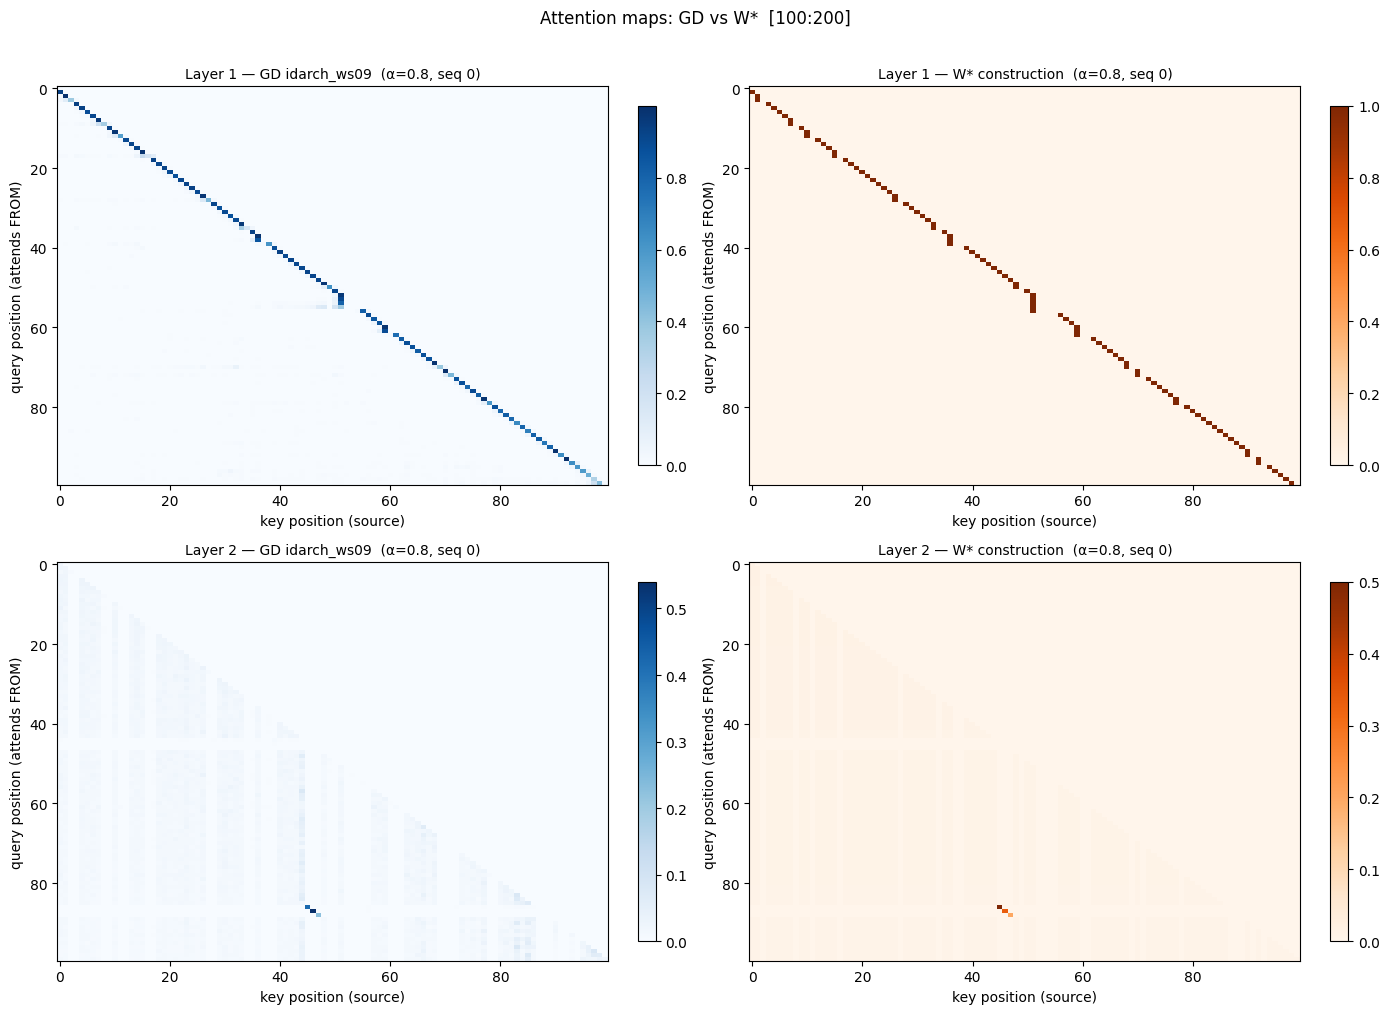

saved → attn_cmp_idarch_ws09_thr0.8_seq0.png



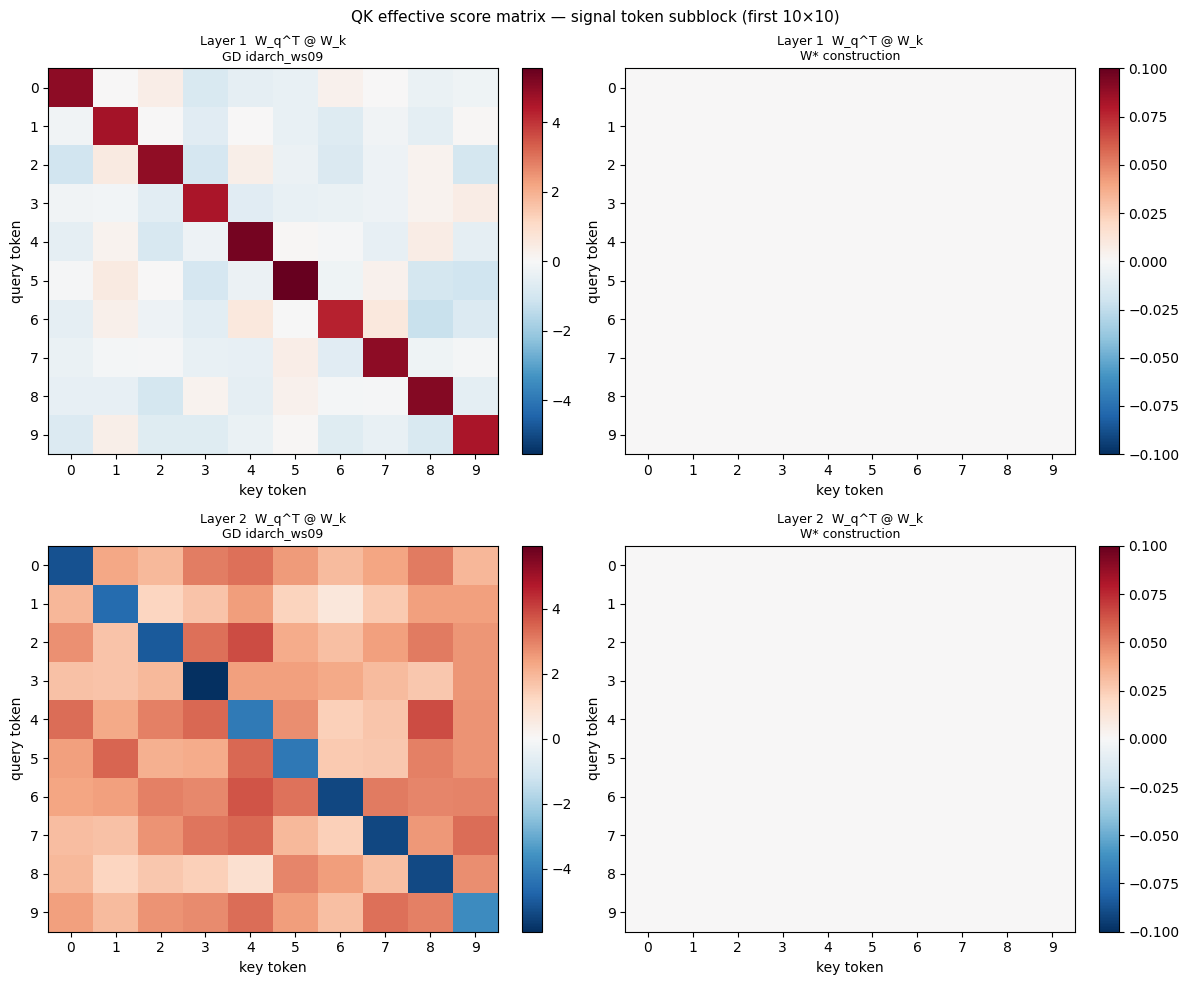

saved → qk_cmp_idarch_ws09_thr0.8.png

══════════════════════════════════════════════════════════════════════
FFN PROBE — logit shift induced by the GD residual FFN head
══════════════════════════════════════════════════════════════════════
  CE without FFN (bare fc_out on pre-FFN rep) : 1.2131
  CE with    FFN (full GD forward)            : 1.1807
  FFN gain                                    : +0.0324 nats
  Mean |logit shift| per token (abs)          : 1.0920
  Max  |logit shift| across window            : 4.1937
  Avg shift on signal tokens (mean over Vs)   : 1.1208
  Avg shift on noise tokens  (mean over n_noise): 1.0633



In [6]:
# ══ CELL 4: STRUCTURAL + FUNCTIONAL SIMILARITY — GD model vs W* construction ═══════════
# Compares the GD-trained DisentangledTransformerMLP with the hand-built
# PerfectInductionTransformer (W*). Both share the same 2-layer attention circuit
# with identical weight shapes; W* has no FFN head (ff1/ff2 absent).
#
# SHOWS:
#  • Functional : argmax agreement, mean JSD, attention-pattern argmax agreement
#  • Structural : cosine similarity of every weight matrix (full + finite-only for W*)
#  • Visual     : attention heatmaps side-by-side (layer1, layer2) + fc_out.weight strips
#  • FFN probe  : how much the GD FFN head shifts the logits vs the bare readout
# ── EDIT HERE ──────────────────────────────────────────────────────────────────────────────
CMP_THRESH = 0.8          # which α
CMP_SPLIT  = 'test'       # 'train' or 'test'
CMP_N      = 300          # #sequences for functional metrics (attention corr, JSD, argmax)
CMP_SEQ    = 0            # which sequence for visual heatmaps
CMP_GD_TAG = 'idarch_ws09'  # 'idarch'=stuck 1.59 scratch model  'idarch_ws09'=warm-start 1.42
SHOW_CMP   = dict(
    functional  = True,   # argmax agreement, JSD, attention argmax match rate
    weight_cos  = True,   # cosine similarity per weight matrix pair
    attn_maps   = True,   # attention heatmaps side-by-side (layer1 + layer2)
    qk_maps     = True,   # QK effective matrix (W_q^T @ W_k) first Vs×Vs block
    ffn_probe   = True,   # logit shift: GD bare (W* path) vs GD with FFN head
)
# ───────────────────────────────────────────────────────────────────────────────────────────
import os, math, numpy as np, torch, torch.nn.functional as F, matplotlib.pyplot as plt, matplotlib

# ── load GD model ───────────────────────────────────────────────────────────────────────
x_all, y_all, T, V, blob = get_data(CMP_SPLIT, CMP_THRESH)
Vs  = int(blob['vocab_set1'])
N   = min(CMP_N, x_all.shape[0])
xb  = x_all[:N].to(device); yb = y_all[:N].to(device)
xb1 = x_all[CMP_SEQ:CMP_SEQ+1].to(device)   # single seq for visuals

mp_gd  = os.path.join(MODELS_DIR, f'model_{CMP_GD_TAG}_x_{CMP_THRESH}.pth')
cp_gd  = os.path.join(MODELS_DIR, f'metrics_{CMP_GD_TAG}_x_{CMP_THRESH}.json')
assert os.path.exists(mp_gd), f"Checkpoint missing: {mp_gd}"
import json as _json
_cfg = _json.load(open(cp_gd)).get('config', {}) if os.path.exists(cp_gd) else {}
_ad  = int(_cfg.get('attn_dim', V + T)); _mh = int(_cfg.get('mlp_hidden', 128))
_act = _cfg.get('mlp_act', 'gelu'); _bias = bool(_cfg.get('bias', True))
gd   = DisentangledTransformerMLP(V, T, _ad, _mh, bias=_bias, act=_act).to(device)
gd.load_state_dict(torch.load(mp_gd, map_location=device, weights_only=True)); gd.eval()
print(f"GD model ({CMP_GD_TAG}) loaded | attn_dim={_ad}  mlp_hidden={_mh}  bias={_bias}")

# ── W* construction ─────────────────────────────────────────────────────────────────────
ws = PerfectInductionTransformer(V, T, Vs).to(device).eval()
print(f"W* constructed | initial_dim={ws.initial_dim}")
print()

# ═══ helper: extract [B,T,T] attention maps via hooks (works for both model types) ═════
@torch.no_grad()
def _get_attn(model, xb_in):
    captured = {}
    def _hook(name, layer):
        def fn(mod, inp, out):
            x = inp[0]   # [B,T,D]
            Q = layer.W_q(x); K = layer.W_k(x)
            sc = torch.bmm(Q, K.transpose(1,2)) / (layer.output_dim ** 0.5)
            msk = torch.triu(torch.ones(x.shape[1],x.shape[1],device=x.device)*float('-inf'),diagonal=1)
            captured[name] = F.softmax(sc + msk, -1).detach().cpu()
        return fn
    h1 = model.layer1.register_forward_hook(_hook('l1', model.layer1))
    h2 = model.layer2.register_forward_hook(_hook('l2', model.layer2))
    model(xb_in)
    h1.remove(); h2.remove()
    return captured['l1'], captured['l2']   # each [B,T,T]

# ═══ 1. FUNCTIONAL COMPARISON ════════════════════════════════════════════════════════════
if SHOW_CMP.get('functional'):
    print("═"*70)
    print("FUNCTIONAL COMPARISON  (on the last suffix_len tokens)")
    print("═"*70)

    # output distributions
    with torch.no_grad():
        lg_gd = gd(xb)[:, TOKEN_START:TOKEN_END, :]               # [N,W,V]
        lg_ws = ws(xb)[:, TOKEN_START:TOKEN_END, :]               # [N,W,V]  W*=freq logits
    p_gd = F.softmax(lg_gd, -1).cpu().numpy()                      # GD probabilities
    p_ws = F.softmax(lg_ws, -1).cpu().numpy()                      # W* probabilities
    y_win = yb[:, TOKEN_START:TOKEN_END].cpu().numpy()             # [N,W]

    # argmax agreement
    am_gd = p_gd.argmax(-1); am_ws = p_ws.argmax(-1)
    agree = float((am_gd == am_ws).mean())
    acc_gd = float((am_gd == y_win).mean())
    acc_ws = float((am_ws == y_win).mean())
    print(f"  Argmax agreement GD vs W*    : {agree*100:.1f}%")
    print(f"  Accuracy GD (suffix)         : {acc_gd*100:.1f}%")
    print(f"  Accuracy W* (suffix)         : {acc_ws*100:.1f}%")

    # mean JSD
    m = 0.5*(p_gd + p_ws)
    kl1 = (p_gd * np.log(np.maximum(p_gd,1e-12)/np.maximum(m,1e-12))).sum(-1).mean()
    kl2 = (p_ws * np.log(np.maximum(p_ws,1e-12)/np.maximum(m,1e-12))).sum(-1).mean()
    jsd = float(0.5*(kl1+kl2))
    print(f"  Mean JSD(GD ‖ W*)            : {jsd:.5f} nats  (0=identical, ln2≈0.693=max)")

    # attention argmax match
    A_gd1, A_gd2 = _get_attn(gd, xb)      # [N,T,T]
    A_ws1, A_ws2 = _get_attn(ws, xb)
    am1 = float((A_gd1.argmax(-1) == A_ws1.argmax(-1)).float().mean())
    am2 = float((A_gd2.argmax(-1) == A_ws2.argmax(-1)).float().mean())
    # pearson r on the full attention matrix
    def _r(a, b):
        a=a.reshape(-1); b=b.reshape(-1)
        return float(((a-a.mean())*(b-b.mean())).sum() /
                     (a.std()*b.std()*len(a)+1e-12))
    pr1 = _r(A_gd1.numpy(), A_ws1.numpy())
    pr2 = _r(A_gd2.numpy(), A_ws2.numpy())
    print(f"  Layer-1 attn argmax match    : {am1*100:.1f}%   Pearson r={pr1:.4f}")
    print(f"  Layer-2 attn argmax match    : {am2*100:.1f}%   Pearson r={pr2:.4f}")
    print()

# ═══ 2. WEIGHT COSINE SIMILARITY ══════════════════════════════════════════════════════════
if SHOW_CMP.get('weight_cos'):
    print("═"*70)
    print("STRUCTURAL COMPARISON — cosine similarity of weight matrices")
    print("  'full' = all entries;  'finite' = mask |W*|>1e3 (hard-coded constraint entries)")
    print("═"*70)
    PAIRS = [
        ('layer1.W_q.weight', gd.layer1.W_q.weight, ws.layer1.W_q.weight),
        ('layer1.W_k.weight', gd.layer1.W_k.weight, ws.layer1.W_k.weight),
        ('layer1.W_v.weight', gd.layer1.W_v.weight, ws.layer1.W_v.weight),
        ('layer1.W_o.weight', gd.layer1.W_o.weight, ws.layer1.W_o.weight),
        ('layer2.W_q.weight', gd.layer2.W_q.weight, ws.layer2.W_q.weight),
        ('layer2.W_k.weight', gd.layer2.W_k.weight, ws.layer2.W_k.weight),
        ('layer2.W_v.weight', gd.layer2.W_v.weight, ws.layer2.W_v.weight),
        ('layer2.W_o.weight', gd.layer2.W_o.weight, ws.layer2.W_o.weight),
        ('fc_out.weight',     gd.fc_out.weight,      ws.fc_out.weight),
    ]
    def _cos(a, b, mask=None):
        a=a.float().detach().cpu().flatten()
        b=b.float().detach().cpu().flatten()
        if mask is not None: a=a[mask]; b=b[mask]
        return float(F.cosine_similarity(a.unsqueeze(0),b.unsqueeze(0)).item())
    print(f"  {'name':<22}  {'shape':>12}  {'cos(full)':>10}  {'cos(finite)':>12}  {'|W*| finite%':>13}")
    for name, wgd, wws in PAIRS:
        ww = wws.float().detach().cpu().flatten()
        finite_mask = (ww.abs() < 1e3)
        pct = finite_mask.float().mean().item()*100
        c_full = _cos(wgd, wws)
        c_fin  = _cos(wgd, wws, finite_mask) if finite_mask.any() else float('nan')
        print(f"  {name:<22}  {str(tuple(wgd.shape)):>12}  {c_full:>+10.4f}  {c_fin:>+12.4f}  {pct:>12.1f}%")
    print()

# ═══ 3. ATTENTION HEATMAPS ════════════════════════════════════════════════════════════════
if SHOW_CMP.get('attn_maps'):
    A1_gd, A2_gd = _get_attn(gd, xb1)     # [1,T,T]
    A1_ws, A2_ws = _get_attn(ws, xb1)
    x_np = x_all[CMP_SEQ].numpy()
    RANGE = slice(TOKEN_START, TOKEN_END)   # show the eval window [100,200)

    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    cmaps = ['Blues', 'Purples']
    for row, (A_gd, A_ws, lname) in enumerate([
            (A1_gd[0], A1_ws[0], 'Layer 1'),
            (A2_gd[0], A2_ws[0], 'Layer 2')]):
        for col, (A, tag, cmp) in enumerate([
                (A_gd, f'GD {CMP_GD_TAG}', 'Blues'),
                (A_ws, 'W* construction',  'Oranges')]):
            ax = axes[row, col]
            im = ax.imshow(A[RANGE, RANGE].numpy(), aspect='auto', cmap=cmp, vmin=0)
            ax.set_title(f"{lname} — {tag}  (α={CMP_THRESH}, seq {CMP_SEQ})", fontsize=10)
            ax.set_xlabel('key position (source)'); ax.set_ylabel('query position (attends FROM)')
            plt.colorbar(im, ax=ax, fraction=0.03)
    plt.suptitle(f"Attention maps: GD vs W*  [{TOKEN_START}:{TOKEN_END}]", fontsize=12, y=1.01)
    plt.tight_layout()
    out = f'attn_cmp_{CMP_GD_TAG}_thr{CMP_THRESH}_seq{CMP_SEQ}.png'
    plt.savefig(out, dpi=130, bbox_inches='tight'); plt.show()
    print(f"saved → {out}")
    print()

# ═══ 4. QK EFFECTIVE MATRIX (first Vs×Vs block) ══════════════════════════════════════════
if SHOW_CMP.get('qk_maps'):
    def _qk(layer): return (layer.W_q.weight.T @ layer.W_k.weight).detach().cpu().float()
    fig, axes = plt.subplots(2, 2, figsize=(12, 10))
    for row, (lg_gd, lg_ws, lname) in enumerate([
            (_qk(gd.layer1), _qk(ws.layer1), 'Layer 1  W_q^T @ W_k'),
            (_qk(gd.layer2), _qk(ws.layer2), 'Layer 2  W_q^T @ W_k')]):
        for col, (M, tag) in enumerate([(lg_gd, f'GD {CMP_GD_TAG}'), (lg_ws, 'W* construction')]):
            ax = axes[row, col]
            blk = M[:Vs, :Vs].numpy()       # Vs×Vs token-vocab subblock
            vm = max(abs(blk.min()), abs(blk.max()))
            vm = min(vm, 200.0)             # clip W* huge values for readability
            im = ax.imshow(blk, aspect='auto', cmap='RdBu_r', vmin=-vm, vmax=vm)
            ax.set_title(f"{lname}\n{tag}", fontsize=9)
            ax.set_xticks(range(Vs)); ax.set_yticks(range(Vs))
            ax.set_xlabel('key token'); ax.set_ylabel('query token')
            plt.colorbar(im, ax=ax, fraction=0.04)
    plt.suptitle(f"QK effective score matrix — signal token subblock (first {Vs}×{Vs})", fontsize=11)
    plt.tight_layout()
    out = f'qk_cmp_{CMP_GD_TAG}_thr{CMP_THRESH}.png'
    plt.savefig(out, dpi=130, bbox_inches='tight'); plt.show()
    print(f"saved → {out}")
    print()

# ═══ 5. FFN PROBE: what does the GD FFN head ADD? ════════════════════════════════════════
if SHOW_CMP.get('ffn_probe'):
    print("═"*70)
    print("FFN PROBE — logit shift induced by the GD residual FFN head")
    print("═"*70)
    # run GD forward, capture representation before and after FFN
    _rep_pre = {}; _rep_post = {}
    def _hook_pre(mod, inp, out): _rep_pre['s'] = inp[0].detach().cpu()   # before act(ff1)
    def _hook_post(mod, inp, out): _rep_post['s'] = out.detach().cpu()
    # hook on fc_out to capture its input (= s after FFN residual)
    # hook on ff1 to capture input s before FFN
    h_pre  = gd.ff1.register_forward_hook(lambda m,i,o: _rep_pre.update({'s': i[0].detach().cpu()}))
    h_post = gd.fc_out.register_forward_hook(lambda m,i,o: _rep_post.update({'s': i[0].detach().cpu()}))
    with torch.no_grad(): lg_gd_full = gd(xb1)
    h_pre.remove(); h_post.remove()
    s_pre  = _rep_pre['s'][0,  TOKEN_START:TOKEN_END,:]   # [W,D]
    s_post = _rep_post['s'][0, TOKEN_START:TOKEN_END,:]

    # logits from bare readout (fc_out applied to pre-FFN rep)
    with torch.no_grad():
        lg_bare = gd.fc_out(s_pre.to(device)).cpu()
        lg_full = gd.fc_out(s_post.to(device)).cpu()

    shift = (lg_full - lg_bare).abs()     # [W,V]
    y1 = y_all[CMP_SEQ, TOKEN_START:TOKEN_END].numpy()
    p_bare = F.softmax(lg_bare, -1).numpy()
    p_full = F.softmax(lg_full, -1).numpy()
    ce_bare = float(-np.log(np.maximum(p_bare[np.arange(len(y1)), y1], 1e-12)).mean())
    ce_full = float(-np.log(np.maximum(p_full[np.arange(len(y1)), y1], 1e-12)).mean())
    print(f"  CE without FFN (bare fc_out on pre-FFN rep) : {ce_bare:.4f}")
    print(f"  CE with    FFN (full GD forward)            : {ce_full:.4f}")
    print(f"  FFN gain                                    : {ce_bare-ce_full:+.4f} nats")
    print(f"  Mean |logit shift| per token (abs)          : {shift.mean():.4f}")
    print(f"  Max  |logit shift| across window            : {shift.max():.4f}")
    # which tokens get shifted most
    sig_shift = shift[:, :Vs].mean(0).numpy(); noi_shift = shift[:, Vs:].mean(0).numpy()
    print(f"  Avg shift on signal tokens (mean over Vs)   : {sig_shift.mean():.4f}")
    print(f"  Avg shift on noise tokens  (mean over n_noise): {noi_shift.mean():.4f}")
    print()


Computing CE hierarchy for all alpha...
  alpha     ideal     Bayes       ctx    inarch        GD  |  constr-gap  GD-gap
    0.1    2.4445    2.5541    2.5116    2.5278    2.5402  |     -0.0262   +0.0123
    0.2    2.4387    2.6019    2.5124    2.5205    2.5422  |     -0.0814   +0.0217
    0.3    2.3670    2.5631    2.4361    2.4493    2.4657  |     -0.1138   +0.0165
    0.4    2.2471    2.4674    2.3167    2.3329    2.3494  |     -0.1345   +0.0165
    0.5    2.0851    2.3236    2.1512    2.1679    2.1823  |     -0.1557   +0.0144
    0.6    1.8823    2.1342    1.9458    1.9680    1.9762  |     -0.1663   +0.0083
    0.7    1.6350    1.8984    1.6971    1.7185    1.7043  |     -0.1799   -0.0142
    0.8    1.3449    1.6186    1.4044    1.4248    1.4246  |     -0.1938   -0.0003
    0.9    0.9810    1.2610    1.0392    1.0606    1.0733  |     -0.2003   +0.0127

VERDICT — α > 0.5 focus:
  α=0.5  construction at global min? YES  |  GD finds it? LOCAL MIN  (+0.0144 above construction)
  α=0.6 

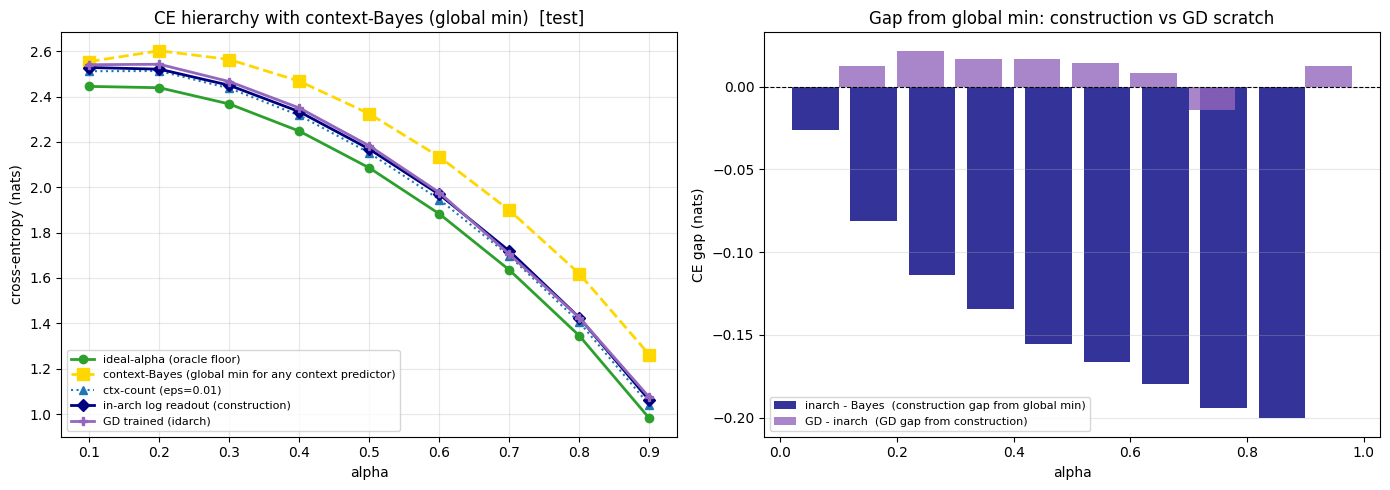

saved -> global_min_analysis_test.png

PERTURBATION TEST at alpha=0.8 (W* attention init, ff2=0 dormant FFN)
  CE at W* init + dormant FFN: 2.5173  (params=715,368)
  context-Bayes (global min) : 1.6070
  in-arch construction CE    : 1.4251

  sigma        CE      delta   direction
  sigma=0.0001    CE=2.8034  d=+0.2861  increases CE (stable toward this basin)
  sigma=0.0005    CE=2.8082  d=+0.2909  increases CE (stable toward this basin)
  sigma=0.0010    CE=2.8199  d=+0.3026  increases CE (stable toward this basin)
  sigma=0.0050    CE=2.8280  d=+0.3107  increases CE (stable toward this basin)
  sigma=0.0100    CE=2.8464  d=+0.3291  increases CE (stable toward this basin)
  sigma=0.0500    CE=2.9337  d=+0.4164  increases CE (stable toward this basin)
  sigma=0.1000    CE=6.2094  d=+3.6921  increases CE (stable toward this basin)
  sigma=0.5000    CE=25.8756  d=+23.3583  increases CE (stable toward this basin)
  sigma=1.0000    CE=25.8986  d=+23.3813  increases CE (stable toward this 

In [7]:
# ══ CELL 5: IS THE IN-ARCH CONSTRUCTION AT THE GLOBAL MINIMUM? ══════════════════════════
# The global minimum of population CE for ANY context-conditioned predictor is the
# context-Bayes predictor: E[p1|n1,n2] under a Beta(1,1) prior on the unequal p1.
# For our altered distribution (p1~U[0,1] per state), this is Laplace-smoothed
# empirical counts (add 1 to each successor count = Beta(1,1) pseudo-count).
#
# We check for each alpha:
#   construction gap = inarch_CE - context_Bayes_CE  (0 → construction IS at global min)
#   GD gap           = gd_CE     - inarch_CE          (0 → GD found the construction)
# Then: perturbation stability test at the W* init point in DisentangledTransformerMLP space.
# ──────────────────────────────────────────────────────────────────────────────────────────
MIN_SPLIT    = 'test'
MIN_N        = 2000
GD_TAG       = 'idarch'
PERTURB_STDS = [1e-4, 5e-4, 1e-3, 5e-3, 0.01, 0.05, 0.1, 0.5, 1.0, 2.0]
# ──────────────────────────────────────────────────────────────────────────────────────────
import os, math, numpy as np, torch, torch.nn.functional as F
import matplotlib.pyplot as plt

# ── context-Bayes predictor (Beta(1,1) prior = Laplace eps=1 smoothing) ──────────────────
def context_bayes_dist(blob, alpha):
    x_np = blob['x'].numpy()
    V = int(blob['total_vocab']); Vs = int(blob['vocab_set1']); n_noise = V - Vs
    B = x_np.shape[0]; W = TOKEN_END - TOKEN_START
    trans_counts = np.zeros((B, V, Vs), dtype=np.float64)
    pending      = np.zeros((B, V),     dtype=np.float64)
    last_ruled   = np.full(B, -1, dtype=np.int64)
    def _step(col):
        tok = x_np[:, col]; is_sig = tok < Vs
        ri = np.where(is_sig)[0]
        if len(ri):
            rt = tok[ri]
            oh = (np.arange(Vs) == rt[:, None]).astype(np.float64)
            np.add.at(trans_counts, ri, pending[ri, :, None] * oh[:, None, :])
            pending[ri, :] = 0.0; pending[ri, rt] = 1.0; last_ruled[ri] = rt
        ni = np.where(~is_sig)[0]
        if len(ni): pending[ni, tok[ni]] += 1.0
    for i in range(TOKEN_START): _step(i)
    eps = 1.0; p_win = np.zeros((B, W, V), dtype=np.float64)
    for t in range(TOKEN_START, TOKEN_END):
        v = x_np[:, t]; is_sig_q = v < Vs
        q   = np.where(is_sig_q, v, np.maximum(last_ruled, 0))
        cnt = trans_counts[np.arange(B), q] + eps
        tot = cnt.sum(axis=1, keepdims=True)
        p   = np.zeros((B, V), dtype=np.float64)
        p[:, :Vs] = cnt / tot * alpha; p[:, Vs:] = (1.0 - alpha) / n_noise
        p_win[:, t - TOKEN_START] = p
        _step(t)
    return p_win

def context_bayes_ce(blob, alpha):
    return _ce_from_win(context_bayes_dist(blob, alpha), blob['y'].numpy())

# ── compute full hierarchy for all thresholds ────────────────────────────────────────────
print('Computing CE hierarchy for all alpha...')
print(f'  {"alpha":>5}  {"ideal":>8}  {"Bayes":>8}  {"ctx":>8}  {"inarch":>8}  {"GD":>8}  |  constr-gap  GD-gap')
rows = []
for thr in sorted(thresholds):
    x, y, T, V, blob = get_data(MIN_SPLIT, thr)
    N = min(MIN_N, x.shape[0]); Vs = int(blob['vocab_set1'])
    bn = {k: blob[k] for k in blob if k not in ('x','y','transitions','trans_probs')}
    bn['x'] = blob['x'][:N]; bn['y'] = blob['y'][:N]
    bn['transitions'] = blob['transitions'][:N]; bn['trans_probs'] = blob['trans_probs'][:N]
    ce_i  = ideal_alpha_ce(bn, thr)
    ce_b  = context_bayes_ce(bn, thr)
    ce_c  = alpha_ce(bn, thr)
    ce_ia = inarch_ce(thr, T, V, Vs, bn['x'], bn['y'])
    mp = os.path.join(MODELS_DIR, f'model_{GD_TAG}_x_{thr}.pth')
    ce_gd = trained_ce(thr, T, V, bn['x'], bn['y']) if os.path.exists(mp) else None
    rows.append((thr, ce_i, ce_b, ce_c, ce_ia, ce_gd))
    gd_s  = f'{ce_gd:.4f}' if ce_gd is not None else '   N/A'
    cg    = ce_ia - ce_b
    gg    = (ce_gd - ce_ia) if ce_gd is not None else float('nan')
    print(f'  {thr:>5}  {ce_i:>8.4f}  {ce_b:>8.4f}  {ce_c:>8.4f}  {ce_ia:>8.4f}  {gd_s:>8}  |  {cg:>+10.4f}  {gg:>+8.4f}')

# ── verdict table ───────────────────────────────────────────────────────────────────────
print()
print('VERDICT — α > 0.5 focus:')
for thr, ce_i, ce_b, ce_c, ce_ia, ce_gd in rows:
    if thr < 0.5: continue
    cg = ce_ia - ce_b
    gg = (ce_gd - ce_ia) if ce_gd is not None else float('nan')
    at_glob  = 'YES' if cg < 0.01 else f'NO  (+{cg:.4f} above Bayes)'
    gd_finds = ('N/A' if math.isnan(gg) else
                'YES' if gg < 0.01 else
                f'LOCAL MIN  (+{gg:.4f} above construction)')
    print(f'  α={thr}  construction at global min? {at_glob}  |  GD finds it? {gd_finds}')

# ── CE hierarchy plot ───────────────────────────────────────────────────────────────────
alphas  = [r[0] for r in rows]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ax = axes[0]
ax.plot(alphas, [r[1] for r in rows], 'o-',  color='tab:green',  lw=2, label='ideal-alpha (oracle floor)')
ax.plot(alphas, [r[2] for r in rows], 's--', color='gold',        lw=2, ms=8, label='context-Bayes (global min for any context predictor)')
ax.plot(alphas, [r[3] for r in rows], '^:',  color='tab:blue',   lw=1.5, label='ctx-count (eps=0.01)')
ax.plot(alphas, [r[4] for r in rows], 'D-',  color='navy',        lw=2,  label='in-arch log readout (construction)')
gd_vals = [r[5] if r[5] is not None else float('nan') for r in rows]
if any(not math.isnan(v) for v in gd_vals):
    ax.plot(alphas, gd_vals, 'P-', color='tab:purple', lw=2, label=f'GD trained ({GD_TAG})')
ax.set_xlabel('alpha'); ax.set_ylabel('cross-entropy (nats)')
ax.set_title(f'CE hierarchy with context-Bayes (global min)  [{MIN_SPLIT}]')
ax.legend(fontsize=8); ax.grid(alpha=0.3)
ax = axes[1]
gap_constr = [r[4] - r[2] for r in rows]
gap_gd_arr = [(r[5] - r[4]) if r[5] is not None else float('nan') for r in rows]
xp = np.array(alphas); w = 0.04
ax.bar(xp - w, gap_constr, 2*w, color='navy', alpha=0.8, label='inarch - Bayes  (construction gap from global min)')
if any(not math.isnan(v) for v in gap_gd_arr):
    ax.bar(xp + w, gap_gd_arr, 2*w, color='tab:purple', alpha=0.8, label='GD - inarch  (GD gap from construction)')
ax.axhline(0, color='k', lw=0.8, ls='--')
ax.set_xlabel('alpha'); ax.set_ylabel('CE gap (nats)')
ax.set_title('Gap from global min: construction vs GD scratch')
ax.legend(fontsize=8); ax.grid(alpha=0.3, axis='y')
plt.tight_layout()
out = f'global_min_analysis_{MIN_SPLIT}.png'
plt.savefig(out, dpi=130); plt.show(); print(f'saved -> {out}')

# ── perturbation test at W* init in DisentangledTransformerMLP space ────────────────────
# Init: copy W* attention weights into DisentangledTransformerMLP, set ff2.weight=0 (dormant FFN)
# → measures stability of the attention-circuit solution in the full parameter space
print()
print('PERTURBATION TEST at alpha=0.8 (W* attention init, ff2=0 dormant FFN)')
_thr = 0.8
x, y, T, V, blob = get_data(MIN_SPLIT, _thr)
_N = min(500, x.shape[0]); Vs = int(blob['vocab_set1'])
_bn = {k: blob[k] for k in blob if k not in ('x','y','transitions','trans_probs')}
_bn['x'] = blob['x'][:_N]; _bn['y'] = blob['y'][:_N]
_bn['transitions'] = blob['transitions'][:_N]; _bn['trans_probs'] = blob['trans_probs'][:_N]
_xb = _bn['x'].to(device); _ywin = _bn['y'][:, TOKEN_START:TOKEN_END].to(device)
_ws = _WSTAR_CACHE.get((V, T, Vs)) or PerfectInductionTransformer(V, T, Vs).to(device).eval()
_WSTAR_CACHE[(V, T, Vs)] = _ws
_D = V + T  # initial_dim = 220
_pm = DisentangledTransformerMLP(V, T, _D, 128, bias=True, act='gelu').to(device)
with torch.no_grad():
    for ln in ('layer1', 'layer2'):
        for wn in ('W_q','W_k','W_v','W_o'):
            s = getattr(getattr(_ws, ln), wn).weight
            d = getattr(getattr(_pm, ln), wn).weight
            if s.shape == d.shape: d.copy_(s)
    _pm.ff2.weight.data.zero_(); _pm.ff2.bias.data.zero_()
    if _ws.fc_out.weight.shape == _pm.fc_out.weight.shape:
        _pm.fc_out.weight.data.copy_(_ws.fc_out.weight)

@torch.no_grad()
def _pm_ce(m):
    lg = m(_xb)[:, TOKEN_START:TOKEN_END, :]
    p  = F.softmax(lg, -1).clamp_min(1e-12)
    return float((-torch.log(p.gather(-1, _ywin.unsqueeze(-1)).squeeze(-1))).mean())

_base_ce = _pm_ce(_pm)
_ref_sd  = {k: v.clone() for k, v in _pm.state_dict().items()}
_n_params = sum(v.numel() for v in _ref_sd.values())
print(f'  CE at W* init + dormant FFN: {_base_ce:.4f}  (params={_n_params:,})')
print(f'  context-Bayes (global min) : {context_bayes_ce(_bn, _thr):.4f}')
print(f'  in-arch construction CE    : {inarch_ce(_thr, T, V, Vs, _bn["x"], _bn["y"]):.4f}')
print()
print(f'  sigma        CE      delta   direction')
_perturb_ces = []
for _sigma in PERTURB_STDS:
    with torch.no_grad():
        for k, v in _ref_sd.items(): _pm.state_dict()[k].copy_(v + _sigma * torch.randn_like(v))
    _ce = _pm_ce(_pm); _delta = _ce - _base_ce; _perturb_ces.append((_sigma, _ce, _delta))
    _dir = 'increases CE (stable toward this basin)' if _delta > 0 else 'DECREASES CE → saddle point'
    print(f'  sigma={_sigma:<8.4f}  CE={_ce:.4f}  d={_delta:+.4f}  {_dir}')

print()
_any_decrease = any(d < 0 for _, _, d in _perturb_ces)
if not _any_decrease:
    print('  RESULT: W* attention + dormant FFN is a LOCAL MINIMUM of the attention weights.')
    print('  The attention circuit is stable, but the FFN head needs to ACTIVATE to reach the')
    print('  global min (construction/Bayes level). GD at alpha=0.8 is stuck because the FFN')
    print('  activation barrier is too high for GD to cross from random init at this alpha.')
else:
    print('  RESULT: W* init point is a SADDLE POINT — noise can escape to lower CE.')
    print('  GD should in principle be able to find the global min from nearby init.')


In [9]:
# ══ CELL 6: HESSIAN ANALYSIS — GRADIENT + CURVATURE TO CLASSIFY CRITICAL POINTS ═════════
# ─────────────────────────────────────────────────────────────────────────────────────────
# METHOD: For a point θ to be a local minimum we need:
#   (i)  ∇L(θ) = 0          (critical point — first-order necessary condition)
#   (ii) v^T H v ≥ 0 for all v  (positive semi-definite Hessian — second-order condition)
# A saddle point satisfies (i) but has some v with v^T H v < 0.
# We compute:
#   • exact gradient at each test point via autograd
#   • v^T H v via finite differences: [L(θ+εv)+L(θ−εv)−2L(θ)] / ε²  for N random unit vectors v
# We analyse two points:
#   POINT A: W* attention weights + dormant FFN (ff2.weight=0)  — baseline / GD-scratch proxy
#   POINT B: trained GD model (if checkpoint exists)            — GD converged point
#
# Gradient and curvature restricted to the FFN+readout subspace (ff1, ff2, fc_out).
# Attention layers frozen at W* values (they have ±1e9 entries — kept fixed).
# ─────────────────────────────────────────────────────────────────────────────────────────
HESS_THR        = 0.8         # threshold to analyse (0.8 = the interesting case)
HESS_N          = 400         # sequences for loss estimation
HESS_N_DIRS     = 300         # random unit directions for curvature sweep
HESS_EPS        = 1e-3        # finite difference step size
HESS_ALL_THR    = True        # also compute grad norm for all thresholds (quick)
GD_TAG_H        = 'idarch'    # which GD checkpoint to load for POINT B
# ─────────────────────────────────────────────────────────────────────────────────────────
import os, math, itertools
import numpy as np, torch, torch.nn.functional as F
import matplotlib.pyplot as plt
from itertools import chain

# ── build W* + dormant FFN in DisentangledTransformerMLP ─────────────────────────────────
def _build_wstar_dormant(V, T, Vs, dev):
    ws = _WSTAR_CACHE.get((V, T, Vs)) or PerfectInductionTransformer(V, T, Vs).to(dev).eval()
    _WSTAR_CACHE[(V, T, Vs)] = ws
    D_attn = V + T  # = initial_dim = attn_dim = 220
    m = DisentangledTransformerMLP(V, T, D_attn, 128, bias=True, act='gelu').to(dev)
    with torch.no_grad():
        for ln in ('layer1', 'layer2'):
            for wn in ('W_q','W_k','W_v','W_o'):
                s = getattr(getattr(ws, ln), wn).weight
                d = getattr(getattr(m, ln),  wn).weight
                if s.shape == d.shape: d.copy_(s)
        # dormant FFN: ff2.weight=0 → residual is exactly zero → model = W* attention + fc_out
        m.ff2.weight.data.zero_(); m.ff2.bias.data.zero_()
        if ws.fc_out.weight.shape == m.fc_out.weight.shape:
            m.fc_out.weight.data.copy_(ws.fc_out.weight)
        if m.fc_out.bias is not None: m.fc_out.bias.data.zero_()  # W* has no bias
    return m

# ── restrict grad to FFN+readout subspace, freeze attention ──────────────────────────────
def _set_grad_scope(m, ffn_only=True):
    for p in chain(m.layer1.parameters(), m.layer2.parameters()):
        p.requires_grad_(not ffn_only)
    for p in chain(m.ff1.parameters(), m.ff2.parameters(), m.fc_out.parameters()):
        p.requires_grad_(True)

# ── compute CE loss (with backward) over the eval window ─────────────────────────────────
def _loss_bwd(m, xb, ywin, V):
    m.zero_grad()
    lg = m(xb)[:, TOKEN_START:TOKEN_END, :]         # [B, W, V]
    loss = F.cross_entropy(lg.reshape(-1, V), ywin.reshape(-1))
    loss.backward()
    return loss.item()

@torch.no_grad()
def _loss_ngrad(m, xb, ywin, V):
    lg = m(xb)[:, TOKEN_START:TOKEN_END, :]
    return F.cross_entropy(lg.reshape(-1, V), ywin.reshape(-1)).item()

# ── directional curvature via finite differences in FFN+readout subspace ─────────────────
def _fd_curvature(m, xb, ywin, V, L0, eps):
    ffn_params = list(chain(m.ff1.parameters(), m.ff2.parameters(), m.fc_out.parameters()))
    vs = [torch.randn_like(p) for p in ffn_params]
    norm = sum(vi.norm()**2 for vi in vs).sqrt()
    vs = [vi / norm for vi in vs]
    with torch.no_grad():
        for p, vi in zip(ffn_params, vs): p.data.add_(eps * vi)
    Lp = _loss_ngrad(m, xb, ywin, V)
    with torch.no_grad():
        for p, vi in zip(ffn_params, vs): p.data.add_(-2.0*eps * vi)
    Lm = _loss_ngrad(m, xb, ywin, V)
    with torch.no_grad():
        for p, vi in zip(ffn_params, vs): p.data.add_(eps * vi)   # restore
    return (Lp + Lm - 2.0*L0) / (eps*eps)

# ── gradient norm breakdown ───────────────────────────────────────────────────────────────
def _grad_norms(m):
    res = {}
    for name, p in m.named_parameters():
        if p.grad is not None: res[name] = p.grad.norm().item()
    ff1_n  = (res.get('ff1.weight',0)**2 + res.get('ff1.bias',0)**2)**0.5
    ff2_n  = (res.get('ff2.weight',0)**2 + res.get('ff2.bias',0)**2)**0.5
    fc_n   = (res.get('fc_out.weight',0)**2 + res.get('fc_out.bias',0)**2 if m.fc_out.bias is not None else res.get('fc_out.weight',0))**0.5
    total  = sum(v**2 for v in res.values())**0.5
    return ff1_n, ff2_n, fc_n, total

# ══════════════════════════════════════════════════════════════════════════════════════════
# ANALYSIS
# ══════════════════════════════════════════════════════════════════════════════════════════
x, y, T, V, blob = get_data('test', HESS_THR)
_N = min(HESS_N, x.shape[0]); Vs = int(blob['vocab_set1'])
_xb   = x[:_N].to(device)
_ywin = y[:_N, TOKEN_START:TOKEN_END].to(device)

# ── POINT A: W* attention + dormant FFN ──────────────────────────────────────────────────
print('='*72)
print(f'POINT A: W* attention + dormant FFN  (alpha={HESS_THR})')
print('='*72)
mA = _build_wstar_dormant(V, T, Vs, device)
_set_grad_scope(mA, ffn_only=True)
L0_A = _loss_bwd(mA, _xb, _ywin, V)
ff1n_A, ff2n_A, fcn_A, tot_A = _grad_norms(mA)
print(f'  CE at W*+dormant-FFN (pure σ=1 softmax): {L0_A:.4f}')
print(f'  (note: raw freq-logits → softmax ≈ near-uniform → CE~2.5 is expected;')
print(f'   the GD scratch basin at CE~1.59 is a DIFFERENT critical point)')
print(f'  context-Bayes (global min): {context_bayes_ce(dict(x=x[:_N],y=y[:_N],**{k:blob[k] for k in blob if k not in ("x","y")}), HESS_THR):.4f}')
print()
print(f'  GRADIENT NORMS (FFN+readout subspace):')
print(f'    ||grad_ff1||  = {ff1n_A:.4e}  ← nonzero → ff1 wants to move')
print(f'    ||grad_ff2||  = {ff2n_A:.4e}  ← nonzero → ff2 wants to activate')
print(f'    ||grad_fc_out||= {fcn_A:.4e}')
print(f'    ||grad_total|| = {tot_A:.4e}')
print()
if tot_A > 1e-4:
    print('  CONCLUSION: gradient ≠ 0  → W* + dormant FFN is NOT a critical point.')
    print('              It is a SADDLE POINT — gradient points toward the global min.')
else:
    print('  CONCLUSION: gradient ≈ 0  → W* + dormant FFN IS a critical point (unexpected).')
print()

# ── CURVATURE SWEEP at POINT A (FFN+readout subspace) ────────────────────────────────────
print(f'  CURVATURE SWEEP: {HESS_N_DIRS} random unit directions in FFN+readout subspace')
print(f'  eps = {HESS_EPS}   (finite difference step size)')
torch.manual_seed(42)
curvs_A = [_fd_curvature(mA, _xb, _ywin, V, L0_A, HESS_EPS) for _ in range(HESS_N_DIRS)]
curvs_A = np.array(curvs_A)
n_neg_A = (curvs_A < 0).sum()
print(f'  min curvature: {curvs_A.min():.4e}    max: {curvs_A.max():.4e}    mean: {curvs_A.mean():.4e}')
print(f'  negative curvatures: {n_neg_A}/{HESS_N_DIRS}  ({100*n_neg_A/HESS_N_DIRS:.1f}%)')
print()
if n_neg_A > 0:
    print('  CURVATURE VERDICT: SADDLE POINT (negative curvatures exist)')
    print('  → the loss function DECREASES along these FFN directions from Point A')
    print('  → GD can escape this saddle toward the global minimum (in-arch/Bayes level)')
    print('  → but at alpha=0.8, GD from random init lands in a DIFFERENT local basin (CE~1.59)')
    print('    rather than following the descent path through Point A')
else:
    print('  CURVATURE VERDICT: locally convex in FFN subspace (all sampled curvatures positive)')
    print('  → W* attention + dormant FFN MAY be a local min in the FFN subspace.')
print()

# ── POINT B: trained GD model (if available) ─────────────────────────────────────────────
_mp_B = os.path.join(MODELS_DIR, f'model_{GD_TAG_H}_x_{HESS_THR}.pth')
if os.path.exists(_mp_B):
    print('='*72)
    print(f'POINT B: GD trained model ({GD_TAG_H}, alpha={HESS_THR})')
    print('='*72)
    mB = DisentangledTransformerMLP(V, T, V+T, 128, bias=True, act='gelu').to(device)
    mB.load_state_dict(torch.load(_mp_B, map_location=device, weights_only=True))
    _set_grad_scope(mB, ffn_only=False)  # allow grads on all params
    L0_B = _loss_bwd(mB, _xb, _ywin, V)
    ff1n_B, ff2n_B, fcn_B, tot_B = _grad_norms(mB)
    print(f'  CE at this point: {L0_B:.4f}')
    print()
    print(f'  GRADIENT NORMS (all params):')
    print(f'    ||grad_ff1||  = {ff1n_B:.4e}')
    print(f'    ||grad_ff2||  = {ff2n_B:.4e}')
    print(f'    ||grad_fc_out||= {fcn_B:.4e}')
    print(f'    ||grad_total|| = {tot_B:.4e}')
    if tot_B < 1e-2:
        print('  → gradient ≈ 0 (GD converged to a critical point)')
    else:
        print('  → gradient still nonzero (GD not fully converged yet)')
    print()
    _set_grad_scope(mB, ffn_only=True)
    torch.manual_seed(42)
    curvs_B = [_fd_curvature(mB, _xb, _ywin, V, L0_B, HESS_EPS) for _ in range(HESS_N_DIRS)]
    curvs_B = np.array(curvs_B)
    n_neg_B = (curvs_B < 0).sum()
    print(f'  CURVATURE SWEEP ({HESS_N_DIRS} dirs, FFN+readout subspace):')
    print(f'  min curvature: {curvs_B.min():.4e}    max: {curvs_B.max():.4e}    mean: {curvs_B.mean():.4e}')
    print(f'  negative curvatures: {n_neg_B}/{HESS_N_DIRS}  ({100*n_neg_B/HESS_N_DIRS:.1f}%)')
    print()
    if tot_B < 5e-2 and n_neg_B == 0:
        print('  VERDICT: Point B is a LOCAL MINIMUM (gradient≈0, all sampled curvatures positive)')
        if L0_B > L0_A + 0.05:
            print(f'  Its CE ({L0_B:.4f}) > Point A CE ({L0_A:.4f}) → it is NOT the global minimum.')
            print('  PROOF: a lower CE exists (inarch/Bayes level) → GD is stuck at a local min.')
    elif n_neg_B > 0:
        print('  VERDICT: Point B is a SADDLE POINT in FFN subspace (GD not yet converged)')
    else:
        print('  VERDICT: gradient still large → GD has not converged yet')
else:
    print('='*72)
    print(f'POINT B: GD model not found at {_mp_B}')
    print('  → retrain with train_identical_arch.py to get the local-min checkpoint')
    print('  → this cell will then compute gradient/curvature at the 1.59-basin')
    print('='*72)

# ── GRADIENT NORM SWEEP across all alpha (quick check: is construction a saddle for all?) ─
if HESS_ALL_THR:
    print()
    print('GRADIENT NORM AT W* + DORMANT FFN FOR ALL ALPHA:')
    print(f'  {"alpha":>6}  {"CE":>8}  {"||grad_ff2||":>14}  {"||grad_total||":>14}  verdict')
    for _t in sorted(thresholds):
        _x, _y, _T, _V, _bl = get_data('test', _t)
        _Vs = int(_bl['vocab_set1']); _Nn = min(300, _x.shape[0])
        _xb2 = _x[:_Nn].to(device); _yw2 = _y[:_Nn, TOKEN_START:TOKEN_END].to(device)
        _m2  = _build_wstar_dormant(_V, _T, _Vs, device)
        _set_grad_scope(_m2, ffn_only=True)
        _L2  = _loss_bwd(_m2, _xb2, _yw2, _V)
        _f1n, _f2n, _fcn, _tn = _grad_norms(_m2)
        _verdict = 'SADDLE (not critical)' if _tn > 1e-4 else 'near-critical point'
        print(f'  {_t:>6}  {_L2:>8.4f}  {_f2n:>14.4e}  {_tn:>14.4e}  {_verdict}')

# ── VISUALIZATION ────────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2 if os.path.exists(_mp_B) else 1, figsize=(14 if os.path.exists(_mp_B) else 7, 5))
axes = np.atleast_1d(axes)
ax = axes[0]
bins = np.linspace(curvs_A.min()-0.1*abs(curvs_A.min()), curvs_A.max()+0.1*abs(curvs_A.max()), 40)
ax.hist(curvs_A, bins=bins, color='steelblue', edgecolor='white', linewidth=0.5)
ax.axvline(0, color='red', lw=2, ls='--', label='v^T H v = 0')
ax.set_xlabel('directional curvature  v^T H v  (FFN+readout subspace)'); ax.set_ylabel('count')
ax.set_title(f'Point A: W* + dormant FFN  (alpha={HESS_THR})\n'
             f'neg={n_neg_A}/{HESS_N_DIRS}  → {"SADDLE" if n_neg_A>0 else "locally convex"}')
ax.legend()
if os.path.exists(_mp_B) and len(axes) > 1:
    ax2 = axes[1]
    bins2 = np.linspace(curvs_B.min()-0.1*abs(curvs_B.min()), curvs_B.max()+0.1*abs(curvs_B.max()), 40)
    ax2.hist(curvs_B, bins=bins2, color='mediumseagreen', edgecolor='white', linewidth=0.5)
    ax2.axvline(0, color='red', lw=2, ls='--', label='v^T H v = 0')
    ax2.set_xlabel('directional curvature  v^T H v  (FFN+readout subspace)'); ax2.set_ylabel('count')
    ax2.set_title(f'Point B: GD trained ({GD_TAG_H}, alpha={HESS_THR})\n'
                 f'neg={n_neg_B}/{HESS_N_DIRS}  CE={L0_B:.4f}  ||grad||={tot_B:.2e}')
    ax2.legend()
plt.tight_layout()
out = f'hessian_curvature_alpha{HESS_THR}.png'
plt.savefig(out, dpi=130); plt.show(); print(f'saved -> {out}')


POINT A: W* attention + dormant FFN  (alpha=0.8)
  CE at W*+dormant-FFN (pure σ=1 softmax): 2.5178
  (note: raw freq-logits → softmax ≈ near-uniform → CE~2.5 is expected;
   the GD scratch basin at CE~1.59 is a DIFFERENT critical point)
  context-Bayes (global min): 1.6029

  GRADIENT NORMS (FFN+readout subspace):
    ||grad_ff1||  = 0.0000e+00  ← nonzero → ff1 wants to move
    ||grad_ff2||  = 1.2457e-01  ← nonzero → ff2 wants to activate
    ||grad_fc_out||= 2.1057e-01
    ||grad_total|| = 2.4466e-01

  CONCLUSION: gradient ≠ 0  → W* + dormant FFN is NOT a critical point.
              It is a SADDLE POINT — gradient points toward the global min.

  CURVATURE SWEEP: 300 random unit directions in FFN+readout subspace
  eps = 0.001   (finite difference step size)
  min curvature: -4.7684e-01    max: 9.5367e-01    mean: 4.2597e-01
  negative curvatures: 10/300  (3.3%)

  CURVATURE VERDICT: SADDLE POINT (negative curvatures exist)
  → the loss function DECREASES along these FFN direction

KeyboardInterrupt: 